# Education Project

## Research questions:

Is school performance correlated with socioeconomic factors?

Our approximation for school performance will be the average ACT score (or converted SAT score) for a particular public school in the United States.

The socioeconomic factors in our dataset are four census tract variables from the area the school is in (unemployment rate, percent of adults with a college degree, percent of children living in a married couple family, and median income), and one is a direct measure of the proportion of students of that school who qualify for free or reduced-price lunch. 

Note: a student qualifies for free or reduced price lunch if their family's income is below 130% or 185% of the Federal poverty line, respectively. https://www.ers.usda.gov/topics/food-nutrition-assistance/child-nutrition-programs/national-school-lunch-program

Specifically, how much do these school-wide factors affect school-wide ACT performance? And how do those effects hold up across school types (charter vs. non-charter) and across the 20 states available in this dataset?

### Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style('whitegrid')

## Import data

I couldn't get the original to load from the link or read the excel file so I downloaded the dataset, converted 'NCESSCH School ID' column to number with 0 decimal places, converted to csv, and accessed it locally.

See code folder for original source.

In [2]:
edgap = pd.read_csv("C:\\Users\\portl\\OneDrive\\Documents\\Data Science Certificate\\DATA 5100 FQ\\Projects\\Education\\data\\EdGap_data_id_fix.csv",
                   dtype = {'NCESSCH School ID': object}
                   )

In [3]:
sch_info = pd.read_csv("C:\\Users\\portl\\OneDrive\\Documents\\Data Science Certificate\\DATA 5100 FQ\\Projects\\Education\\data\\ccd_sch_029_1617_w_1a_11212017.csv",
                       encoding = 'unicode_escape'
                      )

C:\Users\portl\AppData\Local\Temp\ipykernel_28600\3358197441.py:1: DtypeWarning: Columns (0: STATE_AGENCY_NO, 1: LEAID, 2: MSTREET2, 3: MSTREET3, 4: MZIP, 5: MZIP4, 6: LSTREET2, 7: LSTREET3, 8: LZIP, 9: LZIP4, 10: SY_STATUS, 11: UPDATED_STATUS, 12: SCH_TYPE, 13: CHARTAUTH1, 14: CHARTAUTH2, 15: CHARTAUTHN2) have mixed types. Specify dtype option on import or set low_memory=False.
  sch_info = pd.read_csv("C:\\Users\\portl\\OneDrive\\Documents\\Data Science Certificate\\DATA 5100 FQ\\Projects\\Education\\data\\ccd_sch_029_1617_w_1a_11212017.csv",


## First Impressions

In [4]:
edgap.head()

,NCESSCH School ID,CT Unemployment Rate,CT Pct Adults with College Degree,CT Pct Childre In Married Couple Family,CT Median Household Income,School ACT average (or equivalent if SAT score),School Pct Free and Reduced Lunch
0,100001600143,12%,45%,35%,42820.0,20.43,7%
1,100008000024,6%,66%,77%,89320.0,19.50,11%
2,100008000225,6%,70%,71%,84140.0,19.55,10%
3,100017000029,4%,69%,64%,56500.0,17.74,30%
4,100018000040,8%,64%,83%,54015.0,18.25,26%


In [5]:
pd.set_option('display.max_columns', None)
sch_info.head()

,SCHOOL_YEAR,FIPST,STATENAME,ST,SCH_NAME,LEA_NAME,STATE_AGENCY_NO,UNION,ST_LEAID,LEAID,ST_SCHID,NCESSCH,SCHID,MSTREET1,MSTREET2,MSTREET3,MCITY,MSTATE,MZIP,MZIP4,LSTREET1,LSTREET2,LSTREET3,LCITY,LSTATE,LZIP,LZIP4,PHONE,WEBSITE,SY_STATUS,SY_STATUS_TEXT,UPDATED_STATUS,UPDATED_STATUS_TEXT,EFFECTIVE_DATE,SCH_TYPE_TEXT,SCH_TYPE,RECON_STATUS,OUT_OF_STATE_FLAG,CHARTER_TEXT,CHARTAUTH1,CHARTAUTHN1,CHARTAUTH2,CHARTAUTHN2,NOGRADES,G_PK_OFFERED,G_KG_OFFERED,G_1_OFFERED,G_2_OFFERED,G_3_OFFERED,G_4_OFFERED,G_5_OFFERED,G_6_OFFERED,G_7_OFFERED,G_8_OFFERED,G_9_OFFERED,G_10_OFFERED,G_11_OFFERED,G_12_OFFERED,G_13_OFFERED,G_UG_OFFERED,G_AE_OFFERED,GSLO,GSHI,LEVEL,IGOFFERED
0,2016-2017,1,ALABAMA,AL,Sequoyah Sch - Chalkville Campus,Alabama Youth Services,1,NaN,AL-210,100002,AL-210-0020,1.000020e+10,100277.0,P O Box 9486,NaN,NaN,Birmingham,AL,35220,NaN,1000 Industrial School Road,NaN,NaN,Birmingham,AL,35220,NaN,(205)680-8574,http://www.dys.alabama.gov,1,Open,1,Open,03/03/2010,Alternative School,4,No,No,No,NaN,NaN,NaN,NaN,No,No,No,No,No,No,No,No,No,Yes,Yes,Yes,Yes,Yes,Yes,No,No,No,07,12,High,As reported
1,2016-2017,1,ALABAMA,AL,Camps,Alabama Youth Services,1,NaN,AL-210,100002,AL-210-0050,1.000020e+10,101667.0,P O Box 66,NaN,NaN,Mt Meigs,AL,36057,NaN,1601 County Rd. 57,NaN,NaN,Prattville,AL,36067,NaN,(334)215-3850,http://www.dys.alabama.gov,1,Open,1,Open,03/03/2010,Alternative School,4,No,No,No,NaN,NaN,NaN,NaN,No,No,No,No,No,No,No,No,No,Yes,Yes,Yes,Yes,Yes,Yes,No,No,No,07,12,High,As reported
2,2016-2017,1,ALABAMA,AL,Det Ctr,Alabama Youth Services,1,NaN,AL-210,100002,AL-210-0060,1.000020e+10,101670.0,P O Box 66,NaN,NaN,Mt Meigs,AL,36057,NaN,2109 Bashi Rd Bldg 509,NaN,NaN,Thomasville,AL,36784,NaN,(334)215-3850,http://www.dys.alabama.gov,1,Open,1,Open,03/03/2010,Alternative School,4,No,No,No,NaN,NaN,NaN,NaN,No,No,No,No,No,No,No,No,No,Yes,Yes,Yes,Yes,Yes,Yes,No,No,No,07,12,High,As reported
3,2016-2017,1,ALABAMA,AL,Wallace Sch - Mt Meigs Campus,Alabama Youth Services,1,NaN,AL-210,100002,AL-210-0030,1.000020e+10,101705.0,P O Box 66,NaN,NaN,Mount Meigs,AL,36057,NaN,1000 Industrial School Road,NaN,NaN,Mount Meigs,AL,36057,NaN,(334)215-6039,http://www.dys.alabama.gov,1,Open,1,Open,03/03/2010,Alternative School,4,No,No,No,NaN,NaN,NaN,NaN,No,No,No,No,No,No,No,No,No,Yes,Yes,Yes,Yes,Yes,Yes,No,No,No,07,12,High,As reported
4,2016-2017,1,ALABAMA,AL,McNeel Sch - Vacca Campus,Alabama Youth Services,1,NaN,AL-210,100002,AL-210-0040,1.000020e+10,101706.0,8950 Roebuck Blvd,NaN,NaN,Birmingham,AL,35206,NaN,8950 Roebuck Blvd,NaN,NaN,Birmingham,AL,35206,NaN,(205)838-4981,http://www.dys.alabama.gov,1,Open,1,Open,03/03/2010,Alternative School,4,No,No,No,NaN,NaN,NaN,NaN,No,No,No,No,No,No,No,No,No,Yes,Yes,Yes,Yes,Yes,Yes,No,No,No,07,12,High,As reported


In [6]:
edgap.info()

<class 'pandas.DataFrame'>
RangeIndex: 9410 entries, 0 to 9409
Data columns (total 7 columns):
 #   Column                                           Non-Null Count  Dtype  
---  ------                                           --------------  -----  
 0   NCESSCH School ID                                7986 non-null   object 
 1   CT Unemployment Rate                             7972 non-null   str    
 2   CT Pct Adults with College Degree                7973 non-null   str    
 3   CT Pct Childre In Married Couple Family          7961 non-null   str    
 4   CT Median Household Income                       7966 non-null   float64
 5   School ACT average (or equivalent if SAT score)  7986 non-null   float64
 6   School Pct Free and Reduced Lunch                7986 non-null   str    
dtypes: float64(2), object(1), str(4)
memory usage: 607.8+ KB


In [7]:
edgap.tail()

,NCESSCH School ID,CT Unemployment Rate,CT Pct Adults with College Degree,CT Pct Childre In Married Couple Family,CT Median Household Income,School ACT average (or equivalent if SAT score),School Pct Free and Reduced Lunch
9405,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9406,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9407,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9408,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9409,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [8]:
edgap.loc[7980:8000]

,NCESSCH School ID,CT Unemployment Rate,CT Pct Adults with College Degree,CT Pct Childre In Married Couple Family,CT Median Household Income,School ACT average (or equivalent if SAT score),School Pct Free and Reduced Lunch
7980,560522000286,12%,65%,63%,49978.0,19.0,27%
7981,560530200294,3%,59%,72%,64891.0,18.5,23%
7982,560569000311,7%,63%,81%,44603.0,22.3,8%
7983,560569500360,4%,76%,78%,44896.0,21.5,18%
7984,560576200324,6%,67%,88%,92134.0,19.7,11%
7985,560583000335,3%,74%,82%,73849.0,21.8,16%
7986,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7987,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7988,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7989,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Delete all those empty rows

In [9]:
edgap = edgap.loc[:7985]

In [10]:
edgap.info()

<class 'pandas.DataFrame'>
RangeIndex: 7986 entries, 0 to 7985
Data columns (total 7 columns):
 #   Column                                           Non-Null Count  Dtype  
---  ------                                           --------------  -----  
 0   NCESSCH School ID                                7986 non-null   object 
 1   CT Unemployment Rate                             7972 non-null   str    
 2   CT Pct Adults with College Degree                7973 non-null   str    
 3   CT Pct Childre In Married Couple Family          7961 non-null   str    
 4   CT Median Household Income                       7966 non-null   float64
 5   School ACT average (or equivalent if SAT score)  7986 non-null   float64
 6   School Pct Free and Reduced Lunch                7986 non-null   str    
dtypes: float64(2), object(1), str(4)
memory usage: 529.2+ KB


In [11]:
edgap.tail()

,NCESSCH School ID,CT Unemployment Rate,CT Pct Adults with College Degree,CT Pct Childre In Married Couple Family,CT Median Household Income,School ACT average (or equivalent if SAT score),School Pct Free and Reduced Lunch
7981,560530200294,3%,59%,72%,64891.0,18.5,23%
7982,560569000311,7%,63%,81%,44603.0,22.3,8%
7983,560569500360,4%,76%,78%,44896.0,21.5,18%
7984,560576200324,6%,67%,88%,92134.0,19.7,11%
7985,560583000335,3%,74%,82%,73849.0,21.8,16%


Convert percentage strings to floats

In [12]:
edgap["CT Unemployment Rate"] = edgap["CT Unemployment Rate"].str.rstrip("%").astype(float) / 100

In [13]:
edgap["CT Pct Adults with College Degree"] = edgap["CT Pct Adults with College Degree"].str.rstrip("%").astype(float) / 100

In [14]:
edgap["CT Pct Childre In Married Couple Family"] = edgap["CT Pct Childre In Married Couple Family"].str.rstrip("%").astype(float) / 100

In [15]:
edgap["School Pct Free and Reduced Lunch"] = edgap["School Pct Free and Reduced Lunch"].str.rstrip("%").astype(float) / 100

In [16]:
edgap.info()

<class 'pandas.DataFrame'>
RangeIndex: 7986 entries, 0 to 7985
Data columns (total 7 columns):
 #   Column                                           Non-Null Count  Dtype  
---  ------                                           --------------  -----  
 0   NCESSCH School ID                                7986 non-null   object 
 1   CT Unemployment Rate                             7972 non-null   float64
 2   CT Pct Adults with College Degree                7973 non-null   float64
 3   CT Pct Childre In Married Couple Family          7961 non-null   float64
 4   CT Median Household Income                       7966 non-null   float64
 5   School ACT average (or equivalent if SAT score)  7986 non-null   float64
 6   School Pct Free and Reduced Lunch                7986 non-null   float64
dtypes: float64(6), object(1)
memory usage: 436.9+ KB


In [17]:
sch_info.info()

<class 'pandas.DataFrame'>
RangeIndex: 102183 entries, 0 to 102182
Data columns (total 65 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   SCHOOL_YEAR          102183 non-null  str    
 1   FIPST                102183 non-null  int64  
 2   STATENAME            102183 non-null  str    
 3   ST                   102183 non-null  str    
 4   SCH_NAME             102183 non-null  str    
 5   LEA_NAME             102183 non-null  str    
 6   STATE_AGENCY_NO      102183 non-null  object 
 7   UNION                2533 non-null    float64
 8   ST_LEAID             102183 non-null  str    
 9   LEAID                102183 non-null  object 
 10  ST_SCHID             102183 non-null  str    
 11  NCESSCH              102181 non-null  float64
 12  SCHID                102181 non-null  float64
 13  MSTREET1             102181 non-null  str    
 14  MSTREET2             1825 non-null    str    
 15  MSTREET3             28 non-

The school information dataset is far larger, so the EdGap dataset encompasses only a fraction of the schools.

EdGap dataset is missing some values.

NCESSCH school ID is an object in EdGap, but a float in school info.

## Initial Visualizations

Does the data seem sufficient?

A pairplot for all variables

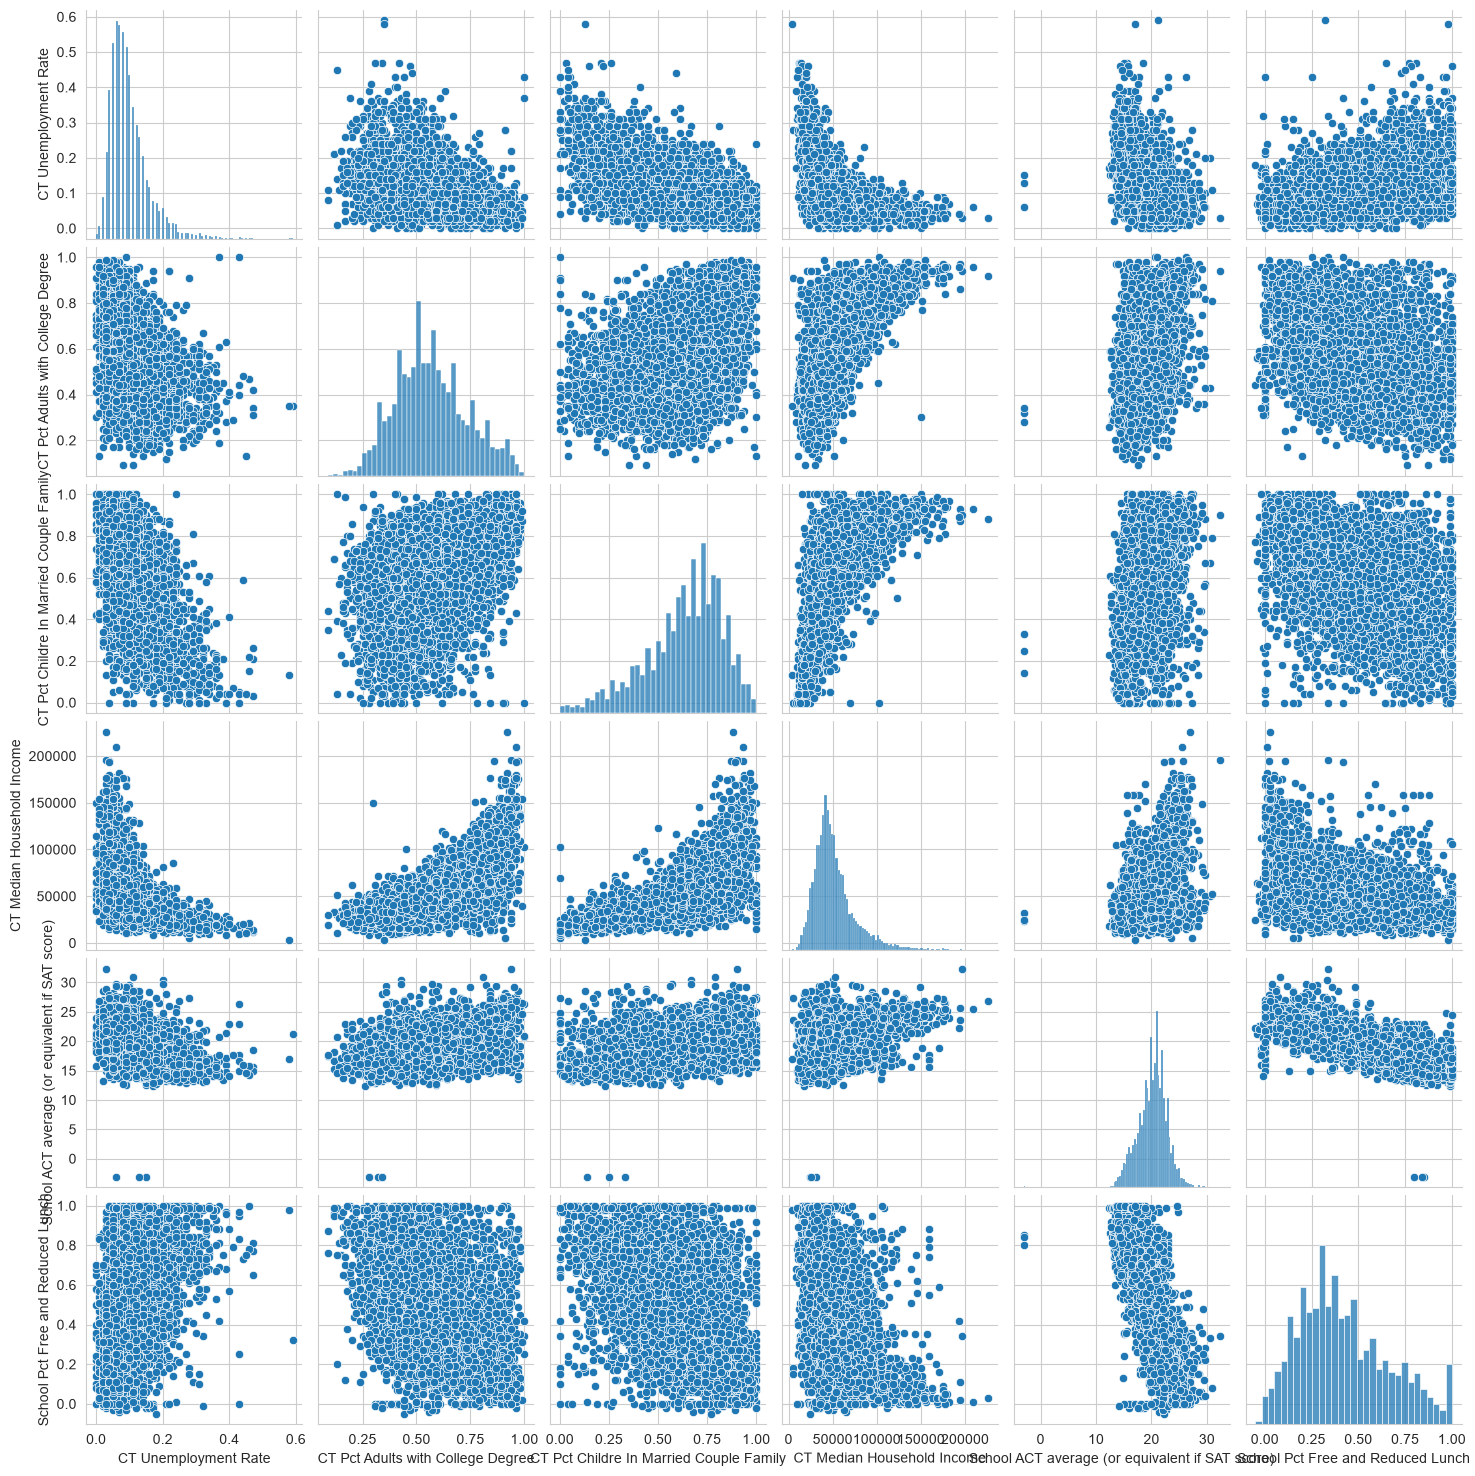

In [18]:
sns.pairplot(edgap.drop(columns = 'NCESSCH School ID'))
plt.show()

A pairplot for just the ACT score row with regression lines added and median household income displayed in scientific notation

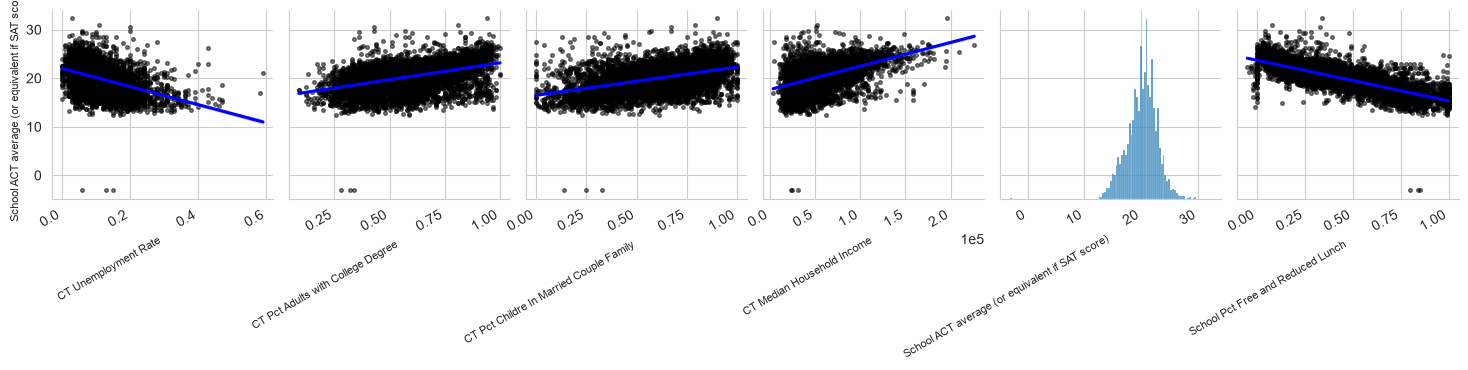

In [19]:
fig = sns.pairplot(
    edgap.drop(columns = 'NCESSCH School ID'),
    y_vars = ['School ACT average (or equivalent if SAT score)'],
    kind = 'reg',
    plot_kws = {'line_kws': {'color': 'blue'},
                'scatter_kws': {'alpha': 0.5, 'color': 'k', 's': 7},
               },
)

for ax in fig.axes.flat:
    if ax.get_xlabel() == 'CT Median Household Income': ax.ticklabel_format(style = 'sci', axis = 'x', scilimits = (0, 0))
    ax.set_xlabel(ax.get_xlabel(), fontsize = 8, rotation = 30, ha = 'right')
    ax.set_ylabel(ax.get_ylabel(), fontsize = 8)

    plt.setp(ax.get_xticklabels(), rotation = 30, ha = 'right')

plt.show()

Relationships can be seen between ACT scores and other variables (as well as some out-of-range values)

## Data selection and polishing

In [20]:
sch_info = sch_info [['SCHOOL_YEAR', 'NCESSCH', 'LSTATE', 'LZIP', 'SCH_TYPE_TEXT', 'LEVEL', 'CHARTER_TEXT']]

In [21]:
sch_info.head()

,SCHOOL_YEAR,NCESSCH,LSTATE,LZIP,SCH_TYPE_TEXT,LEVEL,CHARTER_TEXT
0,2016-2017,1.000020e+10,AL,35220,Alternative School,High,No
1,2016-2017,1.000020e+10,AL,36067,Alternative School,High,No
2,2016-2017,1.000020e+10,AL,36784,Alternative School,High,No
3,2016-2017,1.000020e+10,AL,36057,Alternative School,High,No
4,2016-2017,1.000020e+10,AL,35206,Alternative School,High,No


In [59]:
edgap = edgap.rename(columns = {'NCESSCH School ID': 'id',
                                'CT Pct Adults with College Degree': 'pct_college',
                                'CT Unemployment Rate': 'unemployment_rate',
                                'CT Pct Childre In Married Couple Family': 'pct_married',
                                'CT Median Household Income': 'median_income',
                                'School ACT average (or equivalent if SAT score)': 'act_avg',
                                'School Pct Free and Reduced Lunch': 'pct_lunch',
                               }
                    )

In [60]:
edgap.head()

,id,unemployment_rate,pct_college,pct_married,median_income,act_avg,pct_lunch
0,100001600143,0.12,0.45,0.35,42820.0,20.43,0.07
1,100008000024,0.06,0.66,0.77,89320.0,19.50,0.11
2,100008000225,0.06,0.70,0.71,84140.0,19.55,0.10
3,100017000029,0.04,0.69,0.64,56500.0,17.74,0.30
4,100018000040,0.08,0.64,0.83,54015.0,18.25,0.26


In [61]:
sch_info = sch_info.rename(columns = {'SCHOOL_YEAR': 'year',
                                      'NCESSCH': 'id',
                                      'LSTATE': 'state',
                                      'LZIP': 'zip',
                                      'SCH_TYPE_TEXT': 'sch_type',
                                      'LEVEL': 'level',
                                      'CHARTER_TEXT': 'charter'
                                     }
                          )

In [62]:
sch_info.head()

,year,id,state,zip,sch_type,level,charter
0,2016-2017,1.000020e+10,AL,35220,Alternative School,High,No
1,2016-2017,1.000020e+10,AL,36067,Alternative School,High,No
2,2016-2017,1.000020e+10,AL,36784,Alternative School,High,No
3,2016-2017,1.000020e+10,AL,36057,Alternative School,High,No
4,2016-2017,1.000020e+10,AL,35206,Alternative School,High,No


## Combining data frames

In [63]:
edgap.info()

<class 'pandas.DataFrame'>
RangeIndex: 7986 entries, 0 to 7985
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 7986 non-null   int64  
 1   unemployment_rate  7972 non-null   float64
 2   pct_college        7973 non-null   float64
 3   pct_married        7961 non-null   float64
 4   median_income      7966 non-null   float64
 5   act_avg            7986 non-null   float64
 6   pct_lunch          7986 non-null   float64
dtypes: float64(6), int64(1)
memory usage: 436.9 KB


In [64]:
sch_info.info()

<class 'pandas.DataFrame'>
RangeIndex: 102183 entries, 0 to 102182
Data columns (total 7 columns):
 #   Column    Non-Null Count   Dtype  
---  ------    --------------   -----  
 0   year      102183 non-null  str    
 1   id        102181 non-null  float64
 2   state     102183 non-null  str    
 3   zip       102183 non-null  object 
 4   sch_type  102181 non-null  str    
 5   level     102179 non-null  str    
 6   charter   102179 non-null  str    
dtypes: float64(1), object(1), str(5)
memory usage: 9.0+ MB


In [65]:
exists_in_col = 100001600143 in sch_info['id'].values
exists_in_col

True

Drop those two rows with missing IDs

In [66]:
sch_info_drop = sch_info.dropna(subset = ['id'])

In [67]:
sch_info_drop.info()

<class 'pandas.DataFrame'>
Index: 102181 entries, 0 to 102182
Data columns (total 7 columns):
 #   Column    Non-Null Count   Dtype  
---  ------    --------------   -----  
 0   year      102181 non-null  str    
 1   id        102181 non-null  float64
 2   state     102181 non-null  str    
 3   zip       102181 non-null  object 
 4   sch_type  102179 non-null  str    
 5   level     102179 non-null  str    
 6   charter   102179 non-null  str    
dtypes: float64(1), object(1), str(5)
memory usage: 9.8+ MB


update: casting both id columns as int (Now we can cast as int (to drop floating point) and then object)

I'm not sure this transformation is necessary, but the object was displaying with a floating point and I can't get my dataframes to merge properly so I'm just trying to eliminate as many possible issues as possible.

In [68]:
sch_info_drop['id'] = sch_info_drop['id'].astype(int)

In [69]:
sch_info_drop.info()

<class 'pandas.DataFrame'>
Index: 102181 entries, 0 to 102182
Data columns (total 7 columns):
 #   Column    Non-Null Count   Dtype 
---  ------    --------------   ----- 
 0   year      102181 non-null  str   
 1   id        102181 non-null  int64 
 2   state     102181 non-null  str   
 3   zip       102181 non-null  object
 4   sch_type  102179 non-null  str   
 5   level     102179 non-null  str   
 6   charter   102179 non-null  str   
dtypes: int64(1), object(1), str(5)
memory usage: 9.8+ MB


In [70]:
sch_info_drop.head()

,year,id,state,zip,sch_type,level,charter
0,2016-2017,10000200277,AL,35220,Alternative School,High,No
1,2016-2017,10000201667,AL,36067,Alternative School,High,No
2,2016-2017,10000201670,AL,36784,Alternative School,High,No
3,2016-2017,10000201705,AL,36057,Alternative School,High,No
4,2016-2017,10000201706,AL,35206,Alternative School,High,No


In [71]:
edgap['id'] = edgap['id'].astype(int)

In [72]:
edgap.info()

<class 'pandas.DataFrame'>
RangeIndex: 7986 entries, 0 to 7985
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 7986 non-null   int64  
 1   unemployment_rate  7972 non-null   float64
 2   pct_college        7973 non-null   float64
 3   pct_married        7961 non-null   float64
 4   median_income      7966 non-null   float64
 5   act_avg            7986 non-null   float64
 6   pct_lunch          7986 non-null   float64
dtypes: float64(6), int64(1)
memory usage: 436.9 KB


In [73]:
edgap.head()

,id,unemployment_rate,pct_college,pct_married,median_income,act_avg,pct_lunch
0,100001600143,0.12,0.45,0.35,42820.0,20.43,0.07
1,100008000024,0.06,0.66,0.77,89320.0,19.50,0.11
2,100008000225,0.06,0.70,0.71,84140.0,19.55,0.10
3,100017000029,0.04,0.69,0.64,56500.0,17.74,0.30
4,100018000040,0.08,0.64,0.83,54015.0,18.25,0.26


Now I'm checking to make sure the EdGap IDs I have are genuinely present in the school info data, which, at least, the first one definitely is.

In [74]:
exists_in_col = 100001600143 in sch_info_drop['id'].values
exists_in_col

True

In [75]:
matching_index = sch_info_drop.index[sch_info_drop['id'] == 100001600143].tolist()
matching_index

[19269]

In [76]:
sch_info_drop.iloc[19269]

year             2016-2017
id            100001600143
state                   DE
zip                  19804
sch_type    Regular School
level                 High
charter                Yes
Name: 19269, dtype: object

Merge the dataframes, retaining the school info that matches the IDs found in the EdGap set

In [77]:
df = edgap.merge(sch_info_drop, how = 'left', on = 'id')

And return id type back to object

In [78]:
df['id'] = df['id'].astype(object)

In [79]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7986 entries, 0 to 7985
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 7986 non-null   object 
 1   unemployment_rate  7972 non-null   float64
 2   pct_college        7973 non-null   float64
 3   pct_married        7961 non-null   float64
 4   median_income      7966 non-null   float64
 5   act_avg            7986 non-null   float64
 6   pct_lunch          7986 non-null   float64
 7   year               7898 non-null   str    
 8   state              7898 non-null   str    
 9   zip                7898 non-null   object 
 10  sch_type           7898 non-null   str    
 11  level              7898 non-null   str    
 12  charter            7898 non-null   str    
dtypes: float64(6), object(2), str(5)
memory usage: 1.0+ MB


In [80]:
df.head()

,id,unemployment_rate,pct_college,pct_married,median_income,act_avg,pct_lunch,year,state,zip,sch_type,level,charter
0,100001600143,0.12,0.45,0.35,42820.0,20.43,0.07,2016-2017,DE,19804,Regular School,High,Yes
1,100008000024,0.06,0.66,0.77,89320.0,19.50,0.11,2016-2017,DE,19709,Regular School,High,No
2,100008000225,0.06,0.70,0.71,84140.0,19.55,0.10,2016-2017,DE,19709,Regular School,High,No
3,100017000029,0.04,0.69,0.64,56500.0,17.74,0.30,2016-2017,DE,19958,Regular School,High,No
4,100018000040,0.08,0.64,0.83,54015.0,18.25,0.26,2016-2017,DE,19934,Regular School,High,No


In [81]:
df.tail()

,id,unemployment_rate,pct_college,pct_married,median_income,act_avg,pct_lunch,year,state,zip,sch_type,level,charter
7981,560530200294,0.03,0.59,0.72,64891.0,18.5,0.23,2016-2017,WY,82901,Regular School,High,No
7982,560569000311,0.07,0.63,0.81,44603.0,22.3,0.08,2016-2017,WY,82833,Regular School,High,No
7983,560569500360,0.04,0.76,0.78,44896.0,21.5,0.18,2016-2017,WY,82801,Regular School,High,No
7984,560576200324,0.06,0.67,0.88,92134.0,19.7,0.11,2016-2017,WY,82935,Regular School,High,No
7985,560583000335,0.03,0.74,0.82,73849.0,21.8,0.16,2016-2017,WY,83001,Regular School,High,No


## Quality control

In [82]:
df.select_dtypes(include = ['number']).agg(['min', 'max']).round(2)

,unemployment_rate,pct_college,pct_married,median_income,act_avg,pct_lunch
min,0.00,0.09,0.0,3589.0,-3.07,-0.05
max,0.59,1.00,1.0,226181.0,32.36,1.00


We can see those imossible negative ACT scores and negative percent of students elibile for reduced lunch here

Some other 0.0 and 1.0 values are suspicious, but not inherently incorrect/impossible in a way that we can exclude them outright.

Set out-or-range values to NaN

In [83]:
df.loc[df['pct_lunch'] < 0, 'pct_lunch'] = np.nan

In [84]:
df.loc[df['act_avg'] < 1, 'act_avg'] = np.nan

In [85]:
df['sch_type'].value_counts()

sch_type
Regular School                 7885
Alternative School               10
Special Education School          2
Career and Technical School       1
Name: count, dtype: int64

In [86]:
df['level'].value_counts()

level
High            7230
Other            631
Not reported      35
Elementary         2
Name: count, dtype: int64

Exclude schools that are not high schools, and therefore shouldn't have students taking the ACT

In [87]:
df = df.loc[df['level'] == 'High']

Check for duplicates

In [88]:
df.duplicated().sum()

np.int64(0)

no duplicates found

## Identify Missing Values

In [89]:
df.isna().sum().to_frame(name = 'Number of Missing Values')

,Number of Missing Values
id,0
unemployment_rate,12
pct_college,11
pct_married,20
median_income,16
act_avg,3
pct_lunch,18
year,0
state,0
zip,0


relatively few missing values

### States

In [90]:
df['state'].value_counts()

state
TX    913
OH    654
IL    564
PA    543
MI    498
NC    407
FL    404
GA    367
WI    351
NJ    341
MO    337
IN    321
NY    295
TN    265
WA    263
MA    253
KY    198
LA    194
WY     38
DE     24
Name: count, dtype: int64

In [91]:
df['state'].nunique()

20

we only have info from 20 states

Visualize which states we are getting these data from

In [92]:
import plotly.offline as po
import plotly.graph_objs as pg

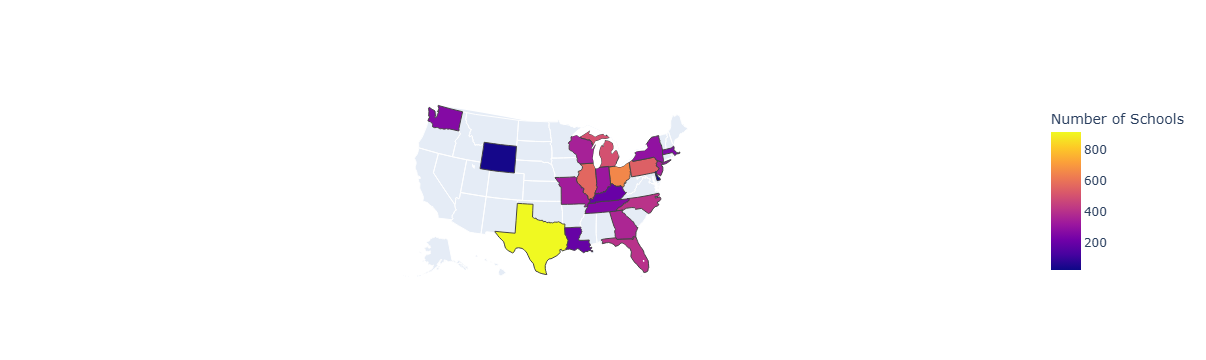

In [93]:
layout = dict(
    geo = {'scope': 'usa'}, coloraxis_colorbar = dict(title = 'Number of Schools')
)

data = dict(
    type = 'choropleth',
    locations = df['state'].value_counts().index,
    locationmode = 'USA-states',
    z = df['state'].value_counts().values,
    coloraxis = 'coloraxis',
)

x = pg.Figure(data = [data], layout = layout)

po.iplot(x)

For this project, we will not be filling in these states with public records

### Drop rows where average ACT score is missing

In [94]:
df = df.dropna(subset = ['act_avg'])

In [95]:
df.isna().sum().to_frame(name = 'Number of Missing Values')

,Number of Missing Values
id,0
unemployment_rate,12
pct_college,11
pct_married,20
median_income,16
act_avg,0
pct_lunch,18
year,0
state,0
zip,0


No other rows NaN values will be dropped because we do not want to lose the other information in those rows. They will be imputed instead.

## Data Imputation

Define predictor variables

In [96]:
predictor_vars = [
    'unemployment_rate',
    'pct_college',
    'pct_married',
    'median_income',
    'pct_lunch',
    'state',
    'charter'
]

Use iterative imputer to replace missing values with a best guess based on a regression relating to the other variables

In [97]:
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer

In [98]:
imputer = IterativeImputer()

Fit imputer using numerical predictor values (categorical values not used as dummies in this case)

In [102]:
numerical_predictors = df[predictor_vars].select_dtypes(include = 'number').columns.to_list()
numerical_predictors

['unemployment_rate',
 'pct_college',
 'pct_married',
 'median_income',
 'pct_lunch']

In [103]:
imputer.fit(df.loc[:, numerical_predictors])

,"estimator estimator: estimator object, default=BayesianRidge()The estimator to use at each step of the round-robin imputation.If `sample_posterior=True`, the estimator must support`return_std` in its `predict` method.",None
,"missing_values missing_values: int or np.nan, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`should be set to `np.nan`, since `pd.NA` will be converted to `np.nan`.",nan
,"sample_posterior sample_posterior: bool, default=FalseWhether to sample from the (Gaussian) predictive posterior of thefitted estimator for each imputation. Estimator must support`return_std` in its `predict` method if set to `True`. Set to`True` if using `IterativeImputer` for multiple imputations.",False
,"max_iter max_iter: int, default=10Maximum number of imputation rounds to perform before returning theimputations computed during the final round. A round is a singleimputation of each feature with missing values. The stopping criterionis met once `max(abs(X_t - X_{t-1}))/max(abs(X[known_vals])) < tol`,where `X_t` is `X` at iteration `t`. Note that early stopping is onlyapplied if `sample_posterior=False`.",10
,"tol tol: float, default=1e-3Tolerance of the stopping condition.",0.001
,"n_nearest_features n_nearest_features: int, default=NoneNumber of other features to use to estimate the missing values ofeach feature column. Nearness between features is measured usingthe absolute correlation coefficient between each feature pair (afterinitial imputation). To ensure coverage of features throughout theimputation process, the neighbor features are not necessarily nearest,but are drawn with probability proportional to correlation for eachimputed target feature. Can provide significant speed-up when thenumber of features is huge. If `None`, all features will be used.",None
,"initial_strategy initial_strategy: {'mean', 'median', 'most_frequent', 'constant'}, default='mean'Which strategy to use to initialize the missing values. Same as the`strategy` parameter in :class:`~sklearn.impute.SimpleImputer`.",'mean'
,"fill_value fill_value: str or numerical value, default=NoneWhen `strategy=""constant""`, `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types... versionadded:: 1.3",None
,"imputation_order imputation_order: {'ascending', 'descending', 'roman', 'arabic', 'random'}, default='ascending'The order in which the features will be imputed. Possible values:- `'ascending'`: From features with fewest missing values to most.- `'descending'`: From features with most missing values to fewest.- `'roman'`: Left to right.- `'arabic'`: Right to left.- `'random'`: A random order for each round.",'ascending'
,"skip_complete skip_complete: bool, default=FalseIf `True` then features with missing values during :meth:`transform`which did not have any missing values during :meth:`fit` will beimputed with the initial imputation method only. Set to `True` if youhave many features with no missing values at both :meth:`fit` and:meth:`transform` time to save compute.",False
,"min_value min_value: float or array-like of shape (n_features,), default=-np.infMinimum possible imputed value. Broadcast to shape `(n_features,)` ifscalar. If array-like, expects shape `(n_features,)`, one min value foreach feature. The default is `-np.inf`... versionchanged:: 0.23 Added support for array-like.",-inf


Replace values

In [104]:
df.loc[:, numerical_predictors] = imputer.transform(df.loc[:, numerical_predictors])

In [105]:
df.isna().sum().to_frame(name = 'Number of Missing Values')

,Number of Missing Values
id,0
unemployment_rate,0
pct_college,0
pct_married,0
median_income,0
act_avg,0
pct_lunch,0
year,0
state,0
zip,0


## Export the clean dataset

In [107]:
df.to_csv('C:\\Users\\portl\\OneDrive\\Documents\\Data Science Certificate\\DATA 5100 FQ\\Projects\\Education\\data\\education_clean.csv',
          encoding = 'utf-8-sig',
          index = False
         )

# Exploratory Data Analysis

### Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style('whitegrid')

# Model preprocessing
from sklearn.preprocessing import StandardScaler

# Modeling
import statsmodels.formula.api as smf
import statsmodels.api as sm

# Model metrics and analysis
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from statsmodels.stats.anova import anova_lm

### Load clean data

In [91]:
df = pd.read_csv('C:\\Users\\portl\\OneDrive\\Documents\\Data Science Certificate\\DATA 5100 FQ\\Projects\\Education\\data\\education_clean.csv')

In [92]:
df.head()

,id,unemployment_rate,pct_college,pct_married,median_income,act_avg,pct_lunch,year,state,zip,sch_type,level,charter
0,100001600143,0.12,0.45,0.35,42820.0,20.43,0.07,2016-2017,DE,19804,Regular School,High,Yes
1,100008000024,0.06,0.66,0.77,89320.0,19.50,0.11,2016-2017,DE,19709,Regular School,High,No
2,100008000225,0.06,0.70,0.71,84140.0,19.55,0.10,2016-2017,DE,19709,Regular School,High,No
3,100017000029,0.04,0.69,0.64,56500.0,17.74,0.30,2016-2017,DE,19958,Regular School,High,No
4,100018000040,0.08,0.64,0.83,54015.0,18.25,0.26,2016-2017,DE,19934,Regular School,High,No


## Examine distributions and relationships

Plot correlation matrix of numerical variables to explore their relationships

In [93]:
# same as before
predictor_vars = [
    'unemployment_rate',
    'pct_college',
    'pct_married',
    'median_income',
    'pct_lunch',
    'state',
    'charter'
]

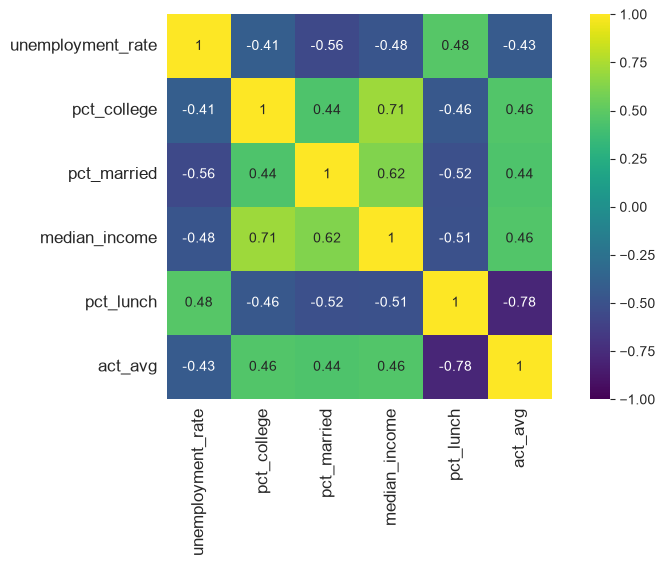

In [94]:
numerical_predictors = df[predictor_vars].select_dtypes(include = 'number').columns.to_list()

corr_matrix = df[numerical_predictors + ['act_avg']].corr()

plt.figure(figsize = (10, 5))

sns.heatmap(corr_matrix, vmax = 1, vmin = -1, square = True, annot = True, cmap = 'viridis')

plt.tick_params(labelsize = 12)

plt.savefig('C:\\Users\\portl\\OneDrive\\Documents\\Data Science Certificate\\DATA 5100 FQ\\Projects\\Education\\reports\\corr_matrix.jpg', dpi = 300, bbox_inches = 'tight')

plt.show()

We can see notable correlative relationships between the average ACT score and our socioeconomic variables, as well as between those variables themselves.

Given the correlations between predictor variables, not all of them may be necessary to use for our analysis.

Further exploration of variable relationships using pair plots

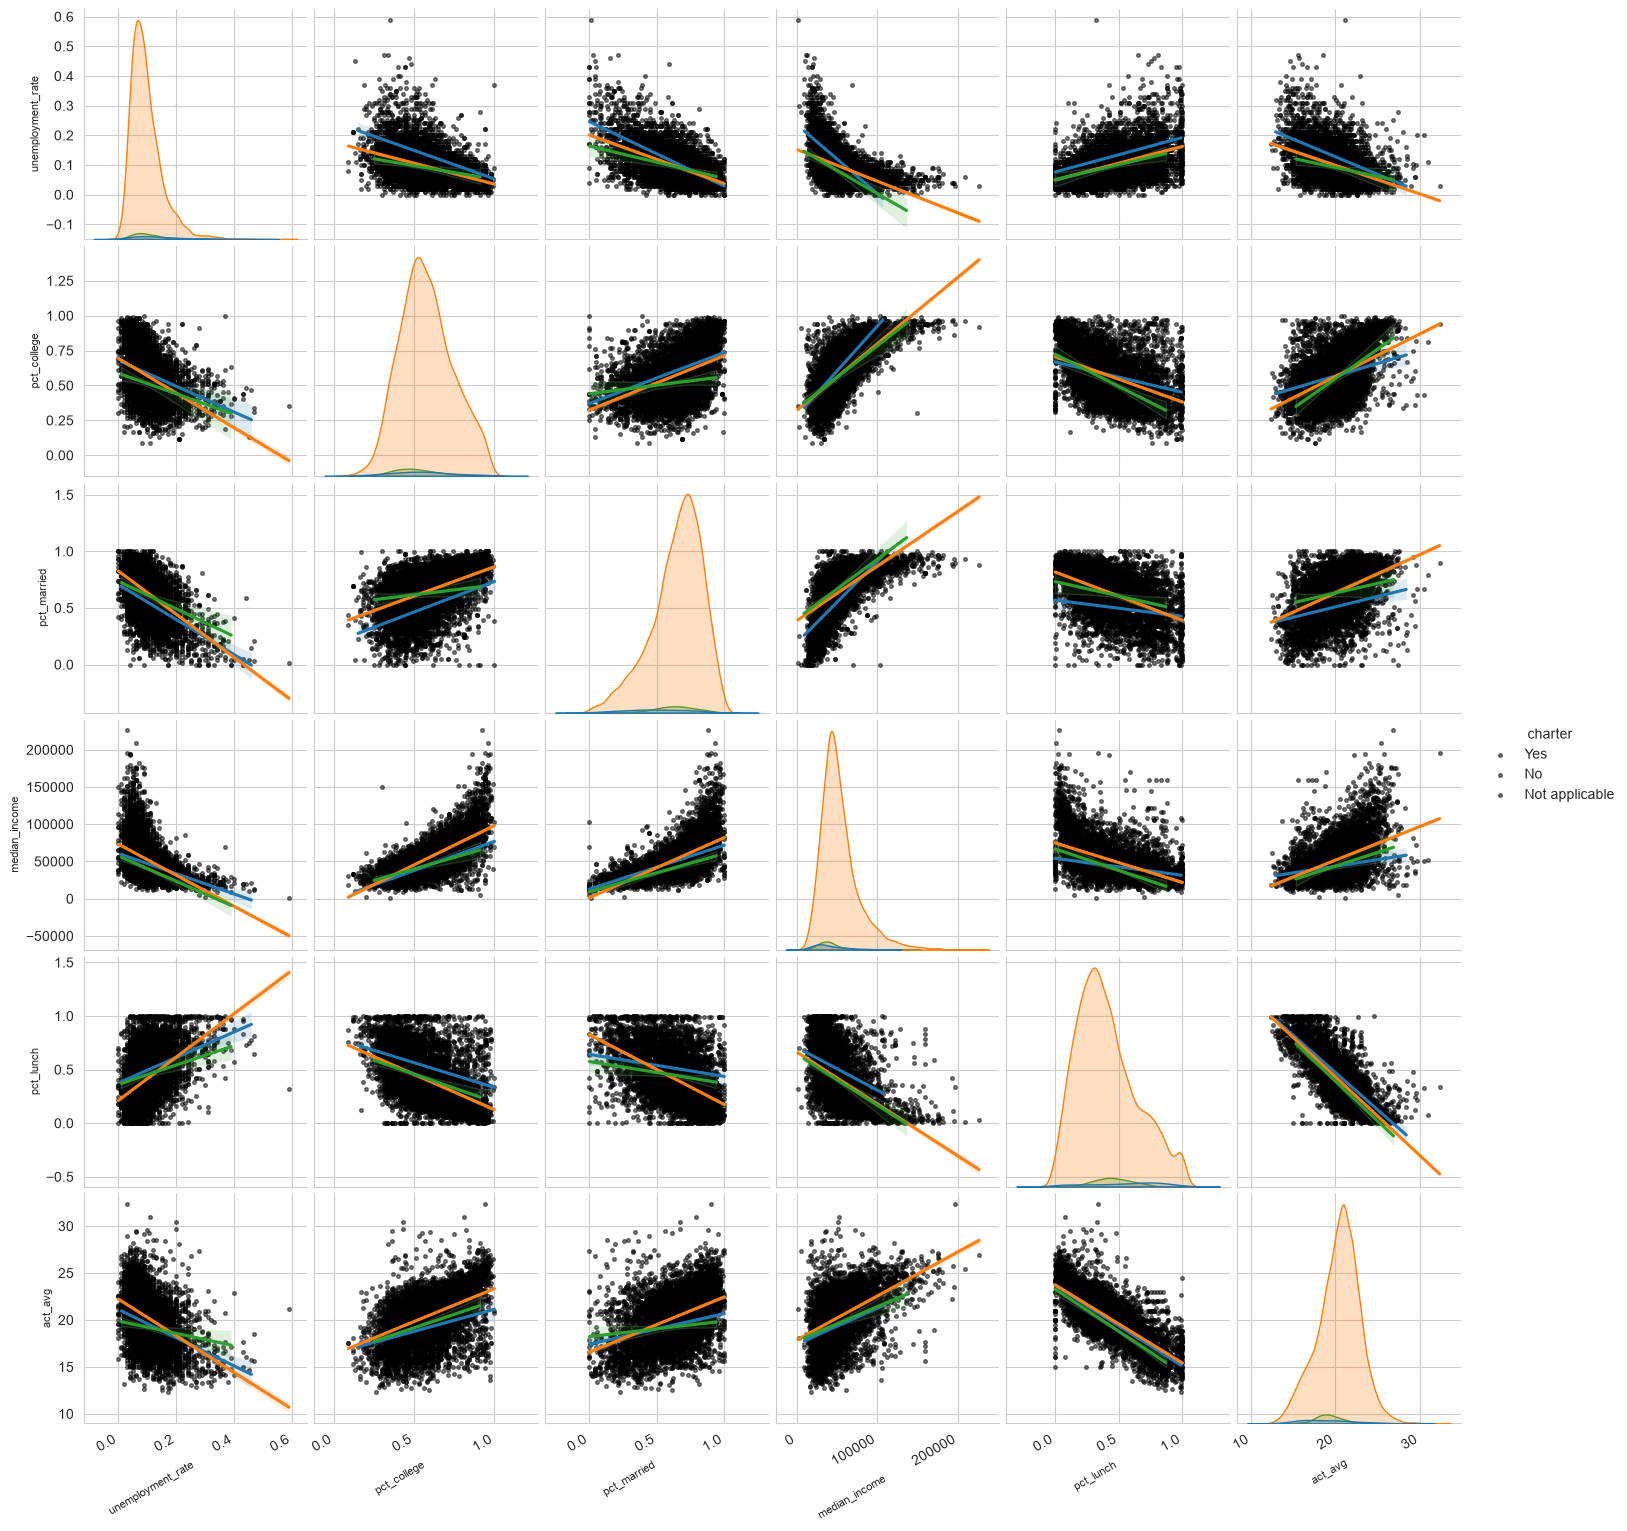

In [88]:
fig = sns.pairplot(
    data = df,
    vars = numerical_predictors + ['act_avg'],
    hue = 'charter', #using charter as a categorical predictor
    kind = 'reg',
    plot_kws = {'scatter_kws': {'alpha': 0.5, 'color': 'k', 's': 7},
               },
)

for ax in fig.axes.flat:
    if ax.get_xlabel() == 'CT Median Household Income':
        ax.ticklabel_format(style = 'sci', axis = 'x', scilimits = (0, 0)) #scientific notation
    ax.set_xlabel(ax.get_xlabel(), fontsize = 8, rotation = 30, ha = 'right')
    ax.set_ylabel(ax.get_ylabel(), fontsize = 8)

    plt.setp(ax.get_xticklabels(), rotation = 30, ha = 'right')

plt.show()

The relationships between the numerical predictors and average ACT score seem roughly linear.

Some variables also have skewed distributions, so some transformation may be useful.

Charter schools (shown in blue (I'm pretty sure)) seem to have similar variable relationships as non-charter schools (shown in orange (I'm quite sure)), but we could test to see if they are significantly different.

In [87]:
sum(df['charter'] == 'Yes')

170

In [88]:
df_charter = (df[df['charter'] == 'Yes'])

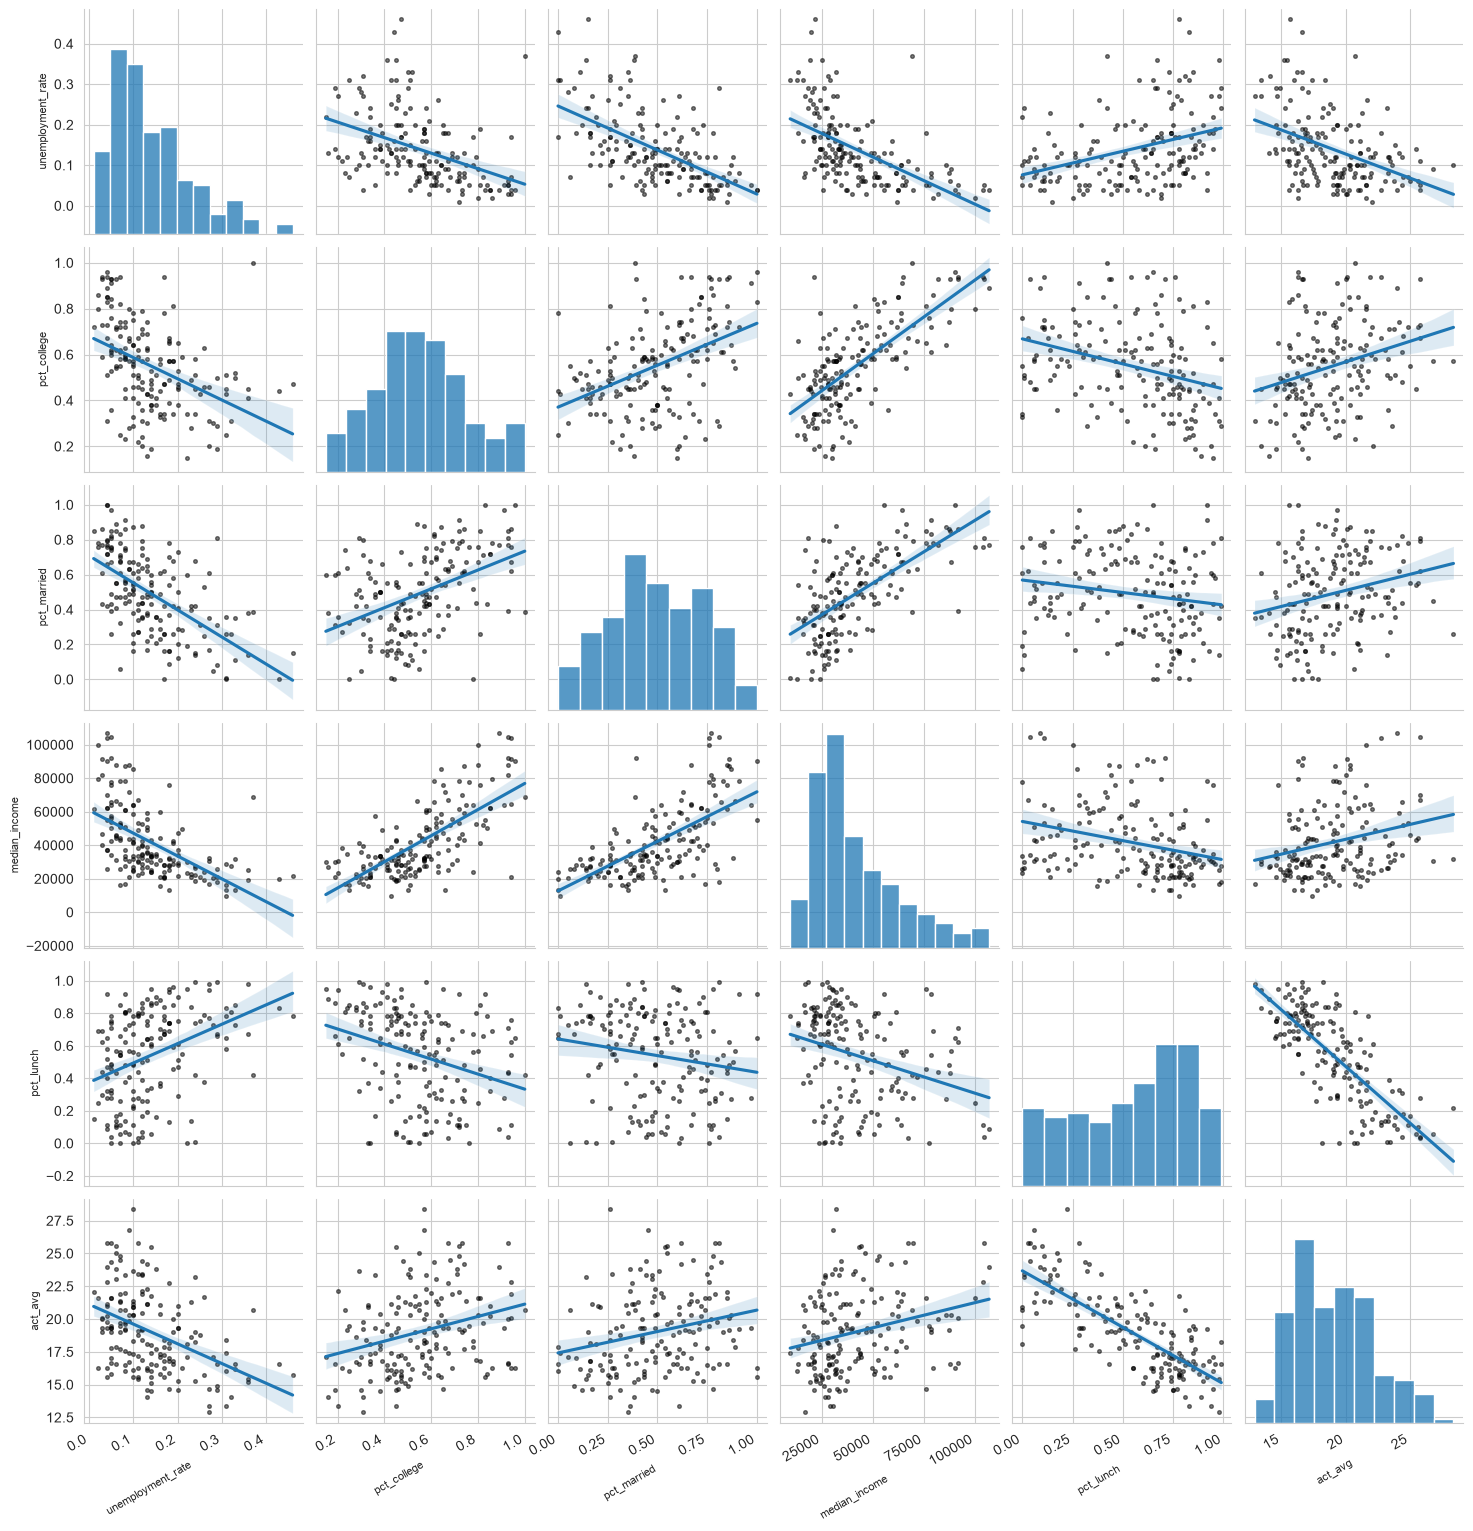

In [89]:
fig = sns.pairplot(
    data = df_charter,
    vars = numerical_predictors + ['act_avg'],
    #hue = 'charter', #using charter as a categorical predictor
    kind = 'reg',
    plot_kws = {'scatter_kws': {'alpha': 0.5, 'color': 'k', 's': 7},
               },
)

for ax in fig.axes.flat:
    if ax.get_xlabel() == 'CT Median Household Income':
        ax.ticklabel_format(style = 'sci', axis = 'x', scilimits = (0, 0)) #scientific notation
    ax.set_xlabel(ax.get_xlabel(), fontsize = 8, rotation = 30, ha = 'right')
    ax.set_ylabel(ax.get_ylabel(), fontsize = 8)

    plt.setp(ax.get_xticklabels(), rotation = 30, ha = 'right')

plt.show()

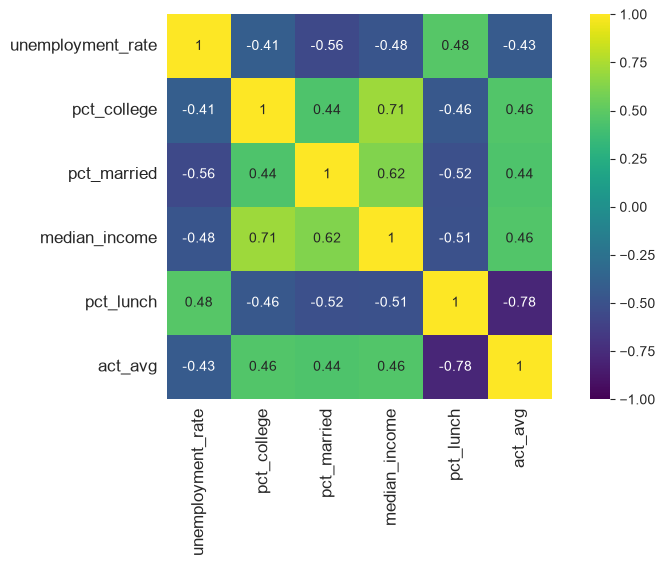

In [95]:
numerical_predictors = df_charter[predictor_vars].select_dtypes(include = 'number').columns.to_list()

corr_matrix_charter = df_charter[numerical_predictors + ['act_avg']].corr()

plt.figure(figsize = (10, 5))

sns.heatmap(corr_matrix, vmax = 1, vmin = -1, square = True, annot = True, cmap = 'viridis')

plt.tick_params(labelsize = 12)

plt.savefig('C:\\Users\\portl\\OneDrive\\Documents\\Data Science Certificate\\DATA 5100 FQ\\Projects\\Education\\reports\\corr_matrix_charter.jpg', dpi = 300, bbox_inches = 'tight')

plt.show()

In [96]:
print(np.abs(corr_matrix - corr_matrix_charter))

                   unemployment_rate  pct_college  pct_married  median_income  \
unemployment_rate           0.000000     0.007673     0.019313       0.087860   
pct_college                 0.007673     0.000000     0.001229       0.001768   
pct_married                 0.019313     0.001229     0.000000       0.028544   
median_income               0.087860     0.001768     0.028544       0.000000   
pct_lunch                   0.102987     0.141903     0.344375       0.202798   
act_avg                     0.010774     0.168321     0.194927       0.199281   

                   pct_lunch   act_avg  
unemployment_rate   0.102987  0.010774  
pct_college         0.141903  0.168321  
pct_married         0.344375  0.194927  
median_income       0.202798  0.199281  
pct_lunch           0.000000  0.009959  
act_avg             0.009959  0.000000  


The largest correlational differences between average ACT score and the socioeconomic factors between charter and non-charter schools are pct_college, pct_married, and median_income, which are not even that different. 

Some of correlational differences between socioeconomic factors between charter and non-charter schools are rather different, though.

However, it's also important to keep in mind that the subset of charter schools is only 170, compared to the over 7,000 of the whole dataset.

## Identify outliers

Using boxplots/IQR to identify outliers. Note: median income is not on a proportion scale (0 < 1), so two plots will be made.

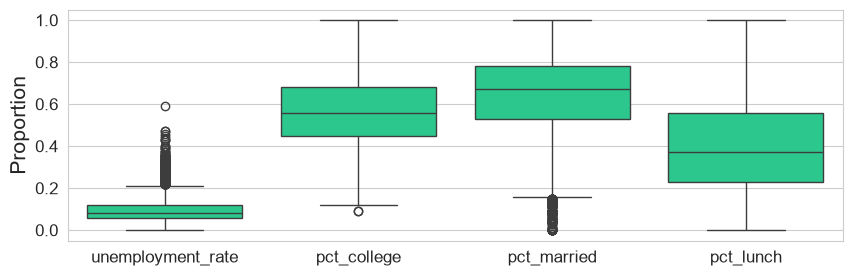

In [122]:
plt.figure(figsize = (10, 3))

fractions = list(numerical_predictors)
fractions.remove('median_income')

sns.boxplot(data = df[fractions], color = sns.xkcd_rgb['aqua green'])

plt.ylabel('Proportion', fontsize = 15)

plt.tick_params(labelsize = 12)

plt.show()

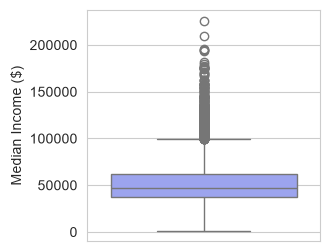

In [121]:
plt.figure(figsize = (3, 3))

sns.boxplot(data = df, y = 'median_income', color = sns.xkcd_rgb['periwinkle blue'])

plt.ylabel('Median Income ($)')

plt.show()

Both plots show outliers, but not to a degree where the numbers are necessarily incorrect.

# Modeling

## Single input models

### Median income

Plot scatterplot together with regression line

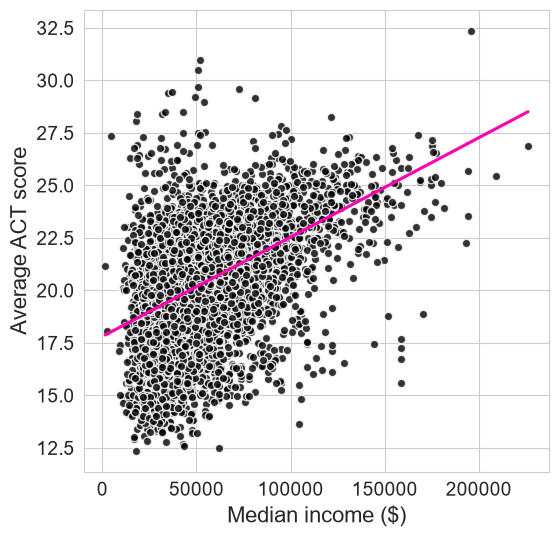

In [59]:
plt.figure(figsize = (6, 6))

sns.regplot(data = df,
           x = 'median_income',
           y = 'act_avg',
           color = sns.xkcd_rgb['bright pink'],
           ci = False,
           scatter_kws = {'color': 'black', 'edgecolors': 'white', 'linewidths': 1})

plt.xlabel('Median income ($)', fontsize = 16)
plt.ylabel('Average ACT score', fontsize = 16)

plt.tick_params(labelsize = 14)

plt.savefig('C:\\Users\\portl\\OneDrive\\Documents\\Data Science Certificate\\DATA 5100 FQ\\Projects\\Education\\reports\\median_income_reg.jpg', dpi = 300, bbox_inches = 'tight')

plt.show()

Fit the simple linear regression model to the whole data frame using formula version of ordinary least squares with average ACT score as response variable and median income as predictor variable.

In [5]:
model_median_income = smf.ols(formula = 'act_avg ~ median_income', data = df).fit()

In [6]:
print(model_median_income.summary())

                            OLS Regression Results                            
Dep. Variable:                act_avg   R-squared:                       0.211
Model:                            OLS   Adj. R-squared:                  0.211
Method:                 Least Squares   F-statistic:                     1934.
Date:                Tue, 13 Oct 2026   Prob (F-statistic):               0.00
Time:                        15:30:02   Log-Likelihood:                -16043.
No. Observations:                7227   AIC:                         3.209e+04
Df Residuals:                    7225   BIC:                         3.210e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept        17.8027      0.063    284.788

note: coefficient for median income is very low due to difference in range

P values are very small (statistically significant coefficients)

But R-squared is low

Numerical assessment of fit accuracy:

Compute R-squared:

In [7]:
model_median_income.rsquared

np.float64(0.21116991206771363)

Compute the RMSE (root mean square error):

In [11]:
y_hat = model_median_income.predict()

In [12]:
np.sqrt(mean_squared_error(df['act_avg'], y_hat)).round(3)

np.float64(2.228)

Compute mean absolute error:

In [13]:
mean_absolute_error(df['act_avg'], y_hat)

1.7129924035349873

error is pretty small relative to the range of ACT scores

A residual plot for graphical assessment of model fit

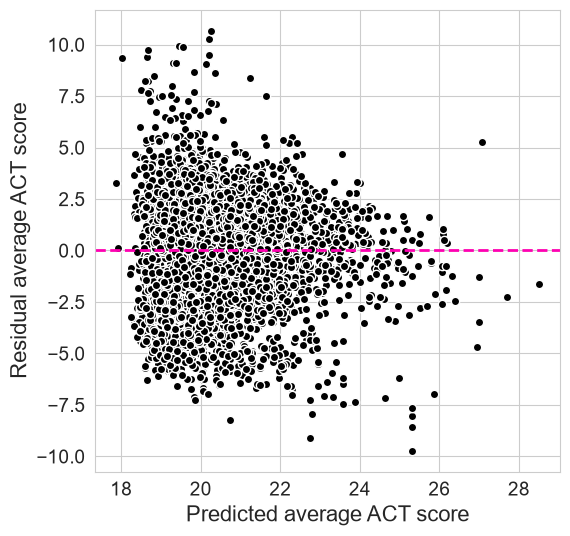

In [16]:
plt.figure(figsize = (6, 6))

plt.plot(y_hat, model_median_income.resid, 'ko', mec = 'w')
plt.axhline(0, color = sns.xkcd_rgb['bright pink'], linestyle = 'dashed', lw = 2)

plt.xlabel('Predicted average ACT score', fontsize = 16)
plt.ylabel('Residual average ACT score', fontsize = 16)

plt.tick_params(labelsize = 14)

plt.show()

The point cloud still has some underlying shape structure to it, so a more complicated model than a simple linear regression may give a better fit.

Quadratic model:

Plot scatterplot with regression curves

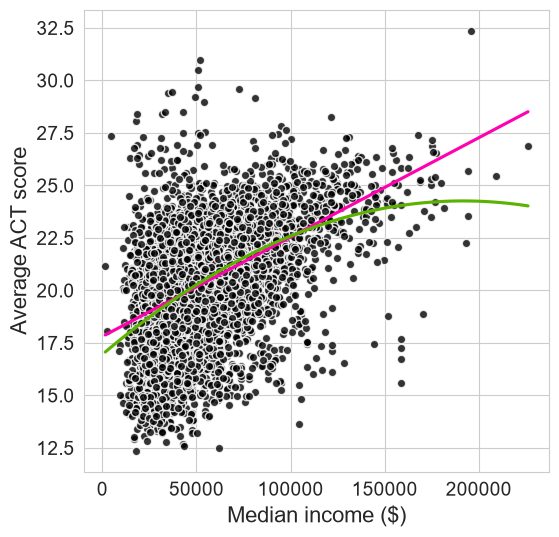

In [20]:
plt.figure(figsize = (6, 6))

sns.regplot(data = df,
           x = 'median_income',
           y = 'act_avg',
           color = sns.xkcd_rgb['bright pink'],
           ci = False,
           scatter_kws = {'color': 'black', 'edgecolors': 'white', 'linewidths': 1})

sns.regplot(data = df,
           x = 'median_income',
           y = 'act_avg',
           order = 2,
           color = sns.xkcd_rgb['kermit green'],
           ci = False,
           scatter = False)

plt.xlabel('Median income ($)', fontsize = 16)
plt.ylabel('Average ACT score', fontsize = 16)

plt.tick_params(labelsize = 14)

plt.show()

The quadratic model is not obviously better, so let's check numerically:

Fit quadratic regression model as before, but add the square of median income

In [22]:
model_median_income2 = smf.ols(formula = 'act_avg ~ median_income + I(median_income ** 2)', data = df).fit()

In [23]:
print(model_median_income2.summary())

                            OLS Regression Results                            
Dep. Variable:                act_avg   R-squared:                       0.219
Model:                            OLS   Adj. R-squared:                  0.219
Method:                 Least Squares   F-statistic:                     1013.
Date:                Tue, 13 Oct 2026   Prob (F-statistic):               0.00
Time:                        16:20:09   Log-Likelihood:                -16007.
No. Observations:                7227   AIC:                         3.202e+04
Df Residuals:                    7224   BIC:                         3.204e+04
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                            coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------
Intercept                16.94

Coefficients are still statistically significant

But R-squared was only slightly improved

Assess the model significance:

In [24]:
model_median_income2.pvalues

Intercept                0.000000e+00
median_income            2.604508e-99
I(median_income ** 2)    1.375816e-17
dtype: float64

Significant linear and quadratic term

In [25]:
anova_lm(model_median_income, model_median_income2)

,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,7225.0,35865.997769,0.0,NaN,NaN,NaN
1,7224.0,35505.940821,1.0,360.056948,73.256794,1.375816e-17


low p-value; statistically significant difference in linear vs quadratic models

Assess model accuracy:

In [27]:
mean_absolute_error(df['act_avg'], model_median_income2.predict())

1.6972780036720119

This mean error is only slightly smaller than for our linear model

A linear model seems sufficient in this case. Although nonlinear transformations of the data may be useful.

### Percent of children in married couple family

Scatterplot with linear regression:

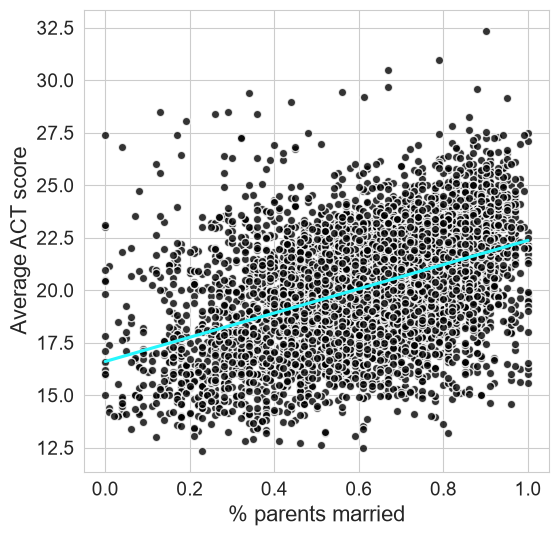

In [60]:
plt.figure(figsize = (6, 6))

sns.regplot(data = df,
           x = 'pct_married',
           y = 'act_avg',
           color = sns.xkcd_rgb['bright light blue'],
           ci = False,
           scatter_kws = {'color': 'black', 'edgecolors': 'white', 'linewidths': 1})

plt.xlabel('% parents married', fontsize = 16)
plt.ylabel('Average ACT score', fontsize = 16)

plt.tick_params(labelsize = 14)

plt.savefig('C:\\Users\\portl\\OneDrive\\Documents\\Data Science Certificate\\DATA 5100 FQ\\Projects\\Education\\reports\\Pct_married_reg.jpg', dpi = 300, bbox_inches = 'tight')

plt.show()

Fit the simple linear regression model to the whole data frame using formula version of ordinary least squares with average ACT score as response variable and pct_married as predictor variable.

In [104]:
model_pct_married = smf.ols(formula = 'act_avg ~ pct_married', data = df).fit()

In [105]:
print(model_pct_married.summary())

                            OLS Regression Results                            
Dep. Variable:                act_avg   R-squared:                       0.194
Model:                            OLS   Adj. R-squared:                  0.193
Method:                 Least Squares   F-statistic:                     1735.
Date:                Sat, 17 Oct 2026   Prob (F-statistic):               0.00
Time:                        13:35:56   Log-Likelihood:                -16123.
No. Observations:                7227   AIC:                         3.225e+04
Df Residuals:                    7225   BIC:                         3.226e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
Intercept      16.6053      0.093    179.412      

p-values are low/significant, but r-squared is also low

Numerical assessment of fit accuracy:

Compute r-squared:

In [106]:
model_pct_married.rsquared

np.float64(0.19359949009822408)

Compute RMSE: (root mean square error)

In [108]:
y_hat = model_pct_married.predict()

In [109]:
np.sqrt(mean_squared_error(df['act_avg'], y_hat)).round(3)

np.float64(2.252)

Compute mean absolute error:

In [110]:
mean_absolute_error(df['act_avg'], y_hat)

1.736206735947009

error is fairly small relative to the range of ACT scores

Residual plot for graphical assessment of fit:

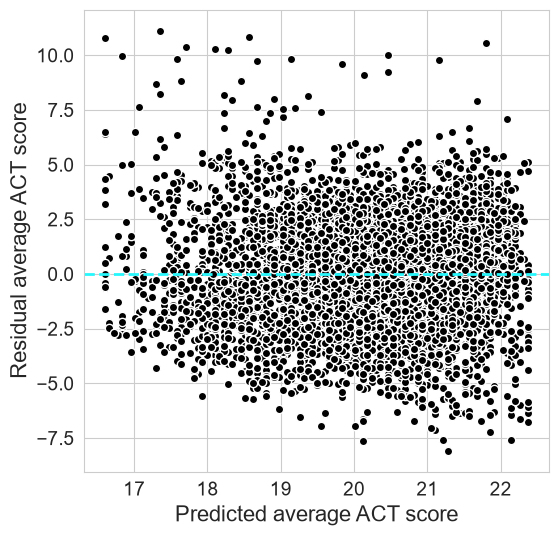

In [111]:
plt.figure(figsize = (6, 6))

plt.plot(y_hat, model_pct_married.resid, 'ko', mec = 'w')
plt.axhline(0, color = sns.xkcd_rgb['bright light blue'], linestyle = 'dashed', lw = 2)

plt.xlabel('Predicted average ACT score', fontsize = 16)
plt.ylabel('Residual average ACT score', fontsize = 16)

plt.tick_params(labelsize = 14)

plt.show()

Point cloud has no underlying shape -> linear model is sufficient

### Percent of students who qualify for reduced price lunch

Plot scatterplot with regression line

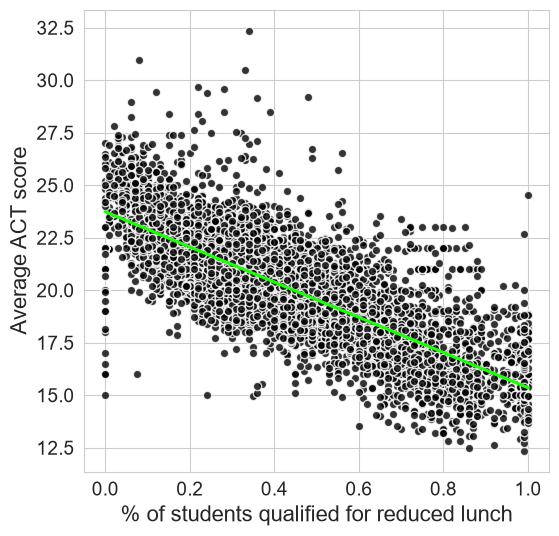

In [58]:
plt.figure(figsize = (6, 6))

sns.regplot(data = df,
           x = 'pct_lunch',
           y = 'act_avg',
           color = sns.xkcd_rgb['electric green'],
           ci = False,
           scatter_kws = {'color': 'black', 'edgecolors': 'white', 'linewidths': 1})

plt.xlabel('% of students qualified for reduced lunch', fontsize = 16)
plt.ylabel('Average ACT score', fontsize = 16)

plt.tick_params(labelsize = 14)

plt.savefig('C:\\Users\\portl\\OneDrive\\Documents\\Data Science Certificate\\DATA 5100 FQ\\Projects\\Education\\reports\\act_lunch.jpg', dpi = 300, bbox_inches = 'tight')
plt.show()

Fit the simple linear regression model to the whole data frame using formula version of ordinary least squares with average ACT score as response variable and percent lunch as predictor variable.

In [51]:
model_pct_lunch = smf.ols(formula = 'act_avg ~ pct_lunch', data = df).fit()

In [52]:
print(model_pct_lunch.summary())

                            OLS Regression Results                            
Dep. Variable:                act_avg   R-squared:                       0.613
Model:                            OLS   Adj. R-squared:                  0.613
Method:                 Least Squares   F-statistic:                 1.146e+04
Date:                Tue, 13 Oct 2026   Prob (F-statistic):               0.00
Time:                        19:14:27   Log-Likelihood:                -13468.
No. Observations:                7227   AIC:                         2.694e+04
Df Residuals:                    7225   BIC:                         2.695e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     23.7383      0.037    641.442      0.0

p-values are very low (statistically significant coefficient)

R-squared is much higher than the median income model

R-squared:

In [53]:
model_pct_lunch.rsquared

np.float64(0.6132407443755764)

RMSE:

In [54]:
y_hat = model_pct_lunch.predict()

In [55]:
np.sqrt(mean_squared_error(df['act_avg'], y_hat)).round(3)

np.float64(1.56)

Mean absolute error:

In [56]:
mean_absolute_error(df['act_avg'], y_hat)

1.1693310728228699

error is quite small for range of ACT scores

A residual plot for graphical assessment of model fit:

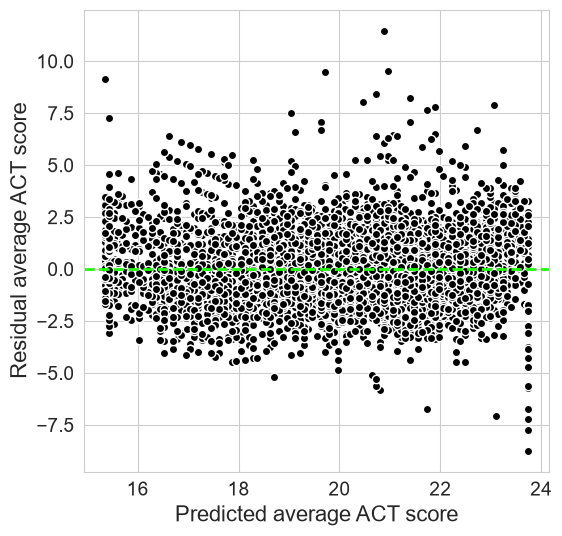

In [57]:
plt.figure(figsize = (6, 6))

plt.plot(y_hat, model_pct_lunch.resid, 'ko', mec = 'w')
plt.axhline(0, color = sns.xkcd_rgb['electric green'], linestyle = 'dashed', lw = 2)

plt.xlabel('Predicted average ACT score', fontsize = 16)
plt.ylabel('Residual average ACT score', fontsize = 16)

plt.tick_params(labelsize = 14)

plt.show()

Point cloud is unstructured, so we can assume that a linear fit is appropriate

## Multiple Linear Regression

### Linear regression model using all socioeconomic variables as predictor variables.

In [76]:
model = smf.ols(
    formula = 'act_avg ~ unemployment_rate + pct_college + pct_married + median_income + pct_lunch',
    data = df).fit()

In [77]:
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                act_avg   R-squared:                       0.627
Model:                            OLS   Adj. R-squared:                  0.627
Method:                 Least Squares   F-statistic:                     2432.
Date:                Sun, 18 Oct 2026   Prob (F-statistic):               0.00
Time:                        19:48:38   Log-Likelihood:                -13333.
No. Observations:                7227   AIC:                         2.668e+04
Df Residuals:                    7221   BIC:                         2.672e+04
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept            22.6756      0.13

pct_married and median_income have large p-values/are not statistically significant

R-squared is notably higher than in the single-variable models

Residual plot for graphical assessment:

In [78]:
y_hat = model.predict()

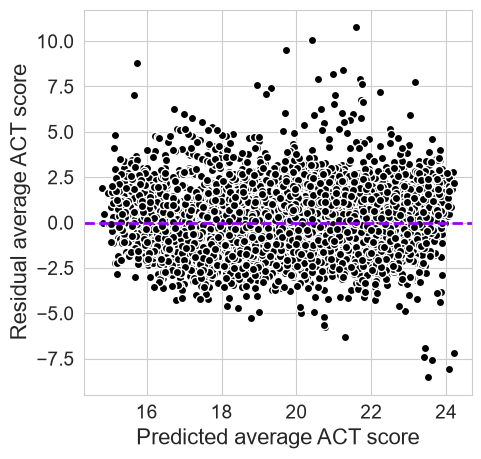

In [79]:
plt.figure(figsize = (5, 5))

plt.plot(y_hat, model.resid, 'ko', mec = 'w')
plt.axhline(0, color = sns.xkcd_rgb['vivid purple'], linestyle = 'dashed', lw = 2)

plt.xlabel('Predicted average ACT score', fontsize = 16)
plt.ylabel('Residual average ACT score', fontsize = 16)

plt.tick_params(labelsize = 14)

plt.show()

Point cloud has little structure, so this seems like a good fit.

Numerical assessment:

In [80]:
mean_absolute_error(df['act_avg'], model.predict())

1.145657431789478

This is a smaller error than in the single predictor models

### Reduced model

Another multiple linear regression model, but excluding the variables that were not found to be significant (percent married and median income.)

In [81]:
model_reduced = smf.ols(formula = 'act_avg ~ unemployment_rate + pct_college + pct_lunch',
                       data = df).fit()

In [71]:
print(model_reduced.summary())

                            OLS Regression Results                            
Dep. Variable:                act_avg   R-squared:                       0.627
Model:                            OLS   Adj. R-squared:                  0.627
Method:                 Least Squares   F-statistic:                     4055.
Date:                Sun, 18 Oct 2026   Prob (F-statistic):               0.00
Time:                        19:48:22   Log-Likelihood:                -13333.
No. Observations:                7227   AIC:                         2.667e+04
Df Residuals:                    7223   BIC:                         2.670e+04
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept            22.6324      0.10

all p-values show that each coefficient is statisticaly significant, as was shown before

Residual plot for graphical assessment

In [72]:
y_hat = model_reduced.predict()

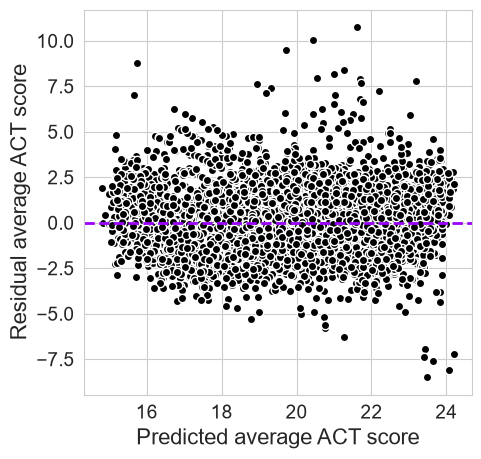

In [73]:
plt.figure(figsize = (5, 5))

plt.plot(y_hat, model_reduced.resid, 'ko', mec = 'w')
plt.axhline(0, color = sns.xkcd_rgb['vivid purple'], linestyle = 'dashed', lw = 2)

plt.xlabel('Predicted average ACT score', fontsize = 16)
plt.ylabel('Residual average ACT score', fontsize = 16)

plt.tick_params(labelsize = 14)

plt.show()

Model still shows good fit after those two variables were removed

In [74]:
mean_absolute_error(df['act_avg'], model_reduced.predict())

1.145768236556789

Let's compare the accuracy between the full and reduced models:

In [82]:
mae_full = mean_absolute_error(df['act_avg'], model.predict())
mae_reduced = mean_absolute_error(df['act_avg'], model_reduced.predict())

r2_full = model.rsquared
r2_reduced = model_reduced.rsquared

pd.DataFrame({'Mean Absolute Error': [mae_full, mae_reduced],
             'R-squared': [r2_full, r2_reduced]},
            index = ['full model', 'reduced model']).round(4)

,Mean Absolute Error,R-squared
full model,1.1457,0.6274
reduced model,1.1458,0.6274


We can see that the reduced model is essentially identical to the full predictor model in terms of accuracy.

ANOVA to test the significance of difference between the two models:

In [83]:
anova_lm(model_reduced, model)

,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,7223.0,16939.619027,0.0,NaN,NaN,NaN
1,7221.0,16938.988163,2.0,0.630863,0.134467,0.874184


No significant difference shown.

## Scaling

Scaling our variables so we can use their coefficients in the model can tell us how much a particular variable is contributing to the outcome (average ACT score)

Scale our predictor variables in our reduced model to mean = 0 and std dev = 1

In [62]:
predictor_variables = ['unemployment_rate', 'pct_college', 'pct_lunch']

In [63]:
scaled_columns = [var + '_normalized' for var in predictor_variables]
print(scaled_columns)

['unemployment_rate_normalized', 'pct_college_normalized', 'pct_lunch_normalized']


Create scaler:

In [64]:
scaler = StandardScaler().fit(df[predictor_variables])

Apply scaler to and add our new columns to our dataframe:

In [65]:
df[scaled_columns] = scaler.transform(df[predictor_variables])

Check for transformation success:

In [66]:
df[scaled_columns].agg(['mean', 'std']).round(3)

,unemployment_rate_normalized,pct_college_normalized,pct_lunch_normalized
mean,-0.0,-0.0,-0.0
std,1.0,1.0,1.0


Fit (reduced) multiple linear regression model with normalized predictors:

In [67]:
model_normalized = smf.ols(formula = 'act_avg ~ unemployment_rate_normalized + pct_college_normalized + pct_lunch_normalized',
                          data = df).fit()

In [68]:
print(model_normalized.summary())

                            OLS Regression Results                            
Dep. Variable:                act_avg   R-squared:                       0.627
Model:                            OLS   Adj. R-squared:                  0.627
Method:                 Least Squares   F-statistic:                     4055.
Date:                Sun, 18 Oct 2026   Prob (F-statistic):               0.00
Time:                        19:48:07   Log-Likelihood:                -13333.
No. Observations:                7227   AIC:                         2.667e+04
Df Residuals:                    7223   BIC:                         2.670e+04
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                                   coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------------
Intercept       

pct_lunch_normalized has the largest magnitude of the three coefficients, making it the strongest predictor (a change in this variable leads to the largest change in the outcome)

In [84]:
mae_normalized = mean_absolute_error(df['act_avg'], model_normalized.predict())
mae_reduced = mean_absolute_error(df['act_avg'], model_reduced.predict())

r2_normalized = model_normalized.rsquared
r2_reduced = model_reduced.rsquared

pd.DataFrame({'Mean Absolute Error': [mae_normalized, mae_reduced],
             'R-squared': [r2_normalized, r2_reduced]},
            index = ['normalized model', 'reduced model']).round(4)

,Mean Absolute Error,R-squared
normalized model,1.1458,0.6274
reduced model,1.1458,0.6274


And we can see that our mean absolute error and r-squared values are unchanged; just our coefficients

Pair plot using our reduced number of predictor variables:

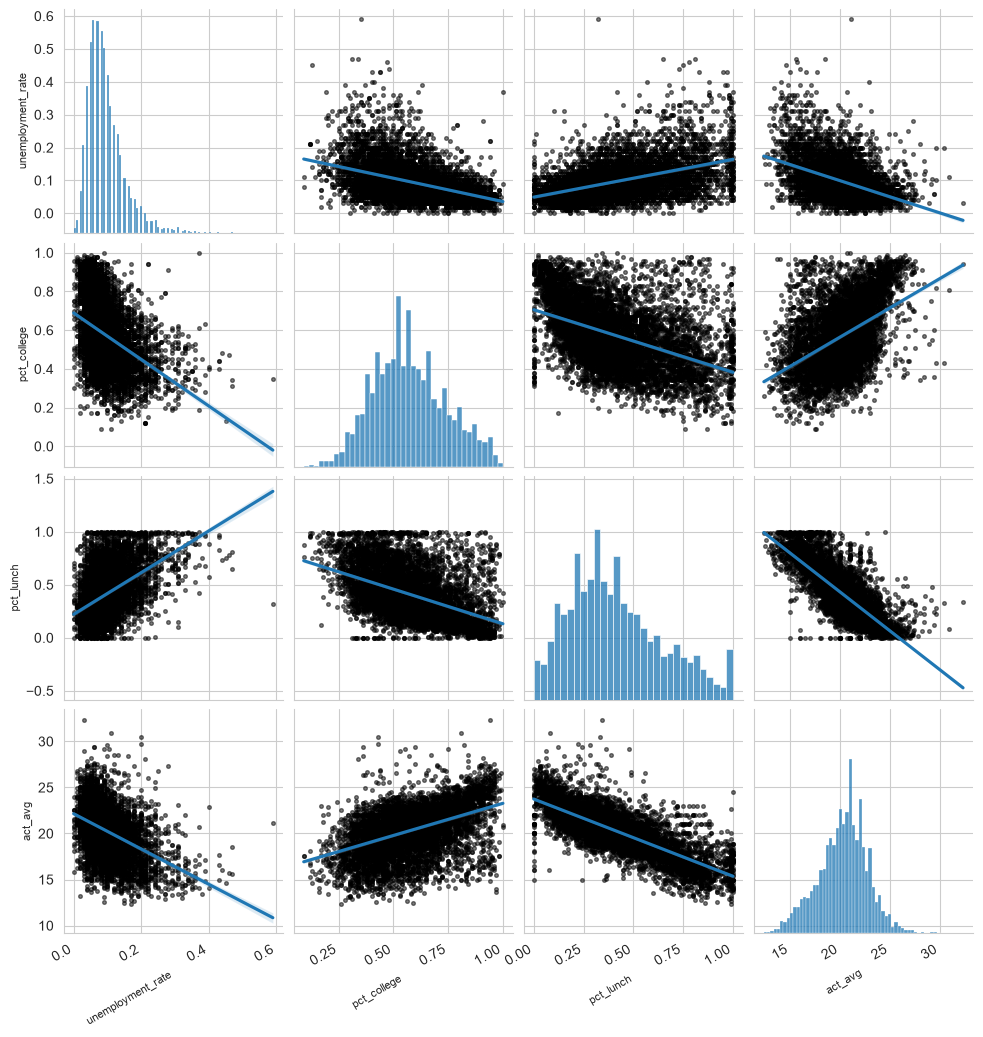

In [85]:
fig = sns.pairplot(
    data = df,
    vars = predictor_variables + ['act_avg'],
    kind = 'reg',
    plot_kws = {'scatter_kws': {'alpha': 0.5, 'color': 'k', 's': 7},
               },
)

for ax in fig.axes.flat:
    ax.set_xlabel(ax.get_xlabel(), fontsize = 8, rotation = 30, ha = 'right')
    ax.set_ylabel(ax.get_ylabel(), fontsize = 8)

    plt.setp(ax.get_xticklabels(), rotation = 30, ha = 'right')

plt.savefig('C:\\Users\\portl\\OneDrive\\Documents\\Data Science Certificate\\DATA 5100 FQ\\Projects\\Education\\reports\\pair_plot_reduced.jpg', dpi = 300, bbox_inches = 'tight')

plt.show()

## State comparisons

Some comparisons of correlations in and between states using all and reduced variables:

In [5]:
numerical_vars = [
    'unemployment_rate',
    'pct_college',
    'pct_married',
    'median_income',
    'pct_lunch',
    'charter'
]

In [6]:
df['state'].value_counts()

state
TX    913
OH    654
IL    564
PA    543
MI    498
NC    407
FL    404
GA    367
WI    351
NJ    338
MO    337
IN    321
NY    295
TN    265
WA    263
MA    253
KY    198
LA    194
WY     38
DE     24
Name: count, dtype: int64

In [9]:
df['state'].nunique()

20

Data from 20 states

A reminder of that state distribution from above:

In [11]:
import plotly.offline as po
import plotly.graph_objs as pg

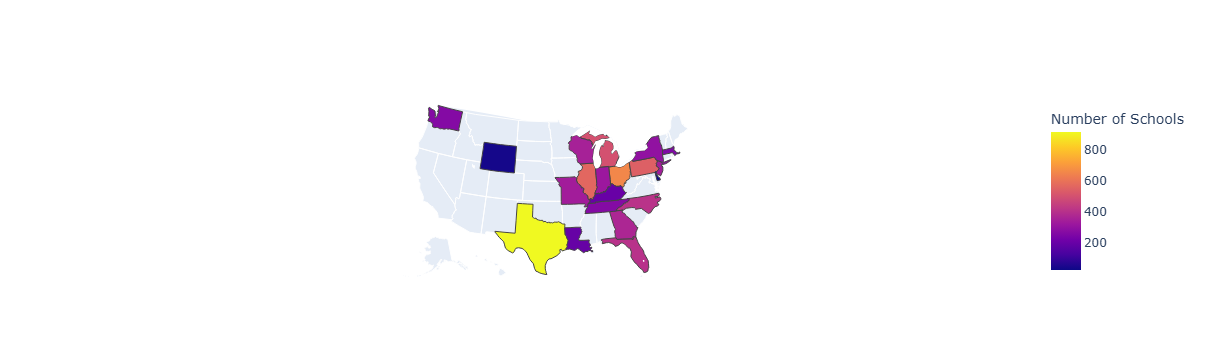

In [12]:
layout = dict(
    geo = {'scope': 'usa'}, coloraxis_colorbar = dict(title = 'Number of Schools')
)

data = dict(
    type = 'choropleth',
    locations = df['state'].value_counts().index,
    locationmode = 'USA-states',
    z = df['state'].value_counts().values,
    coloraxis = 'coloraxis',
)

x = pg.Figure(data = [data], layout = layout)

po.iplot(x)

In [ ]:
#df_charter = (df[df['charter'] == 'Yes'])

Let's see how much ACT scores vary between states:

In [20]:
state_act_avg = df.groupby(['state'])['act_avg'].mean()
state_act_avg

state
DE    17.388333
FL    20.335470
GA    19.569101
IL    19.804787
IN    20.706885
KY    19.265657
LA    18.912887
MA    21.864625
MI    19.581124
MO    20.745697
NC    20.401548
NJ    20.883757
NY    17.659085
OH    21.139144
PA    20.825580
TN    18.950943
TX    20.227010
WA    21.390760
WI    22.018803
WY    19.989474
Name: act_avg, dtype: float64

Boxplot of average ACT scores per state:

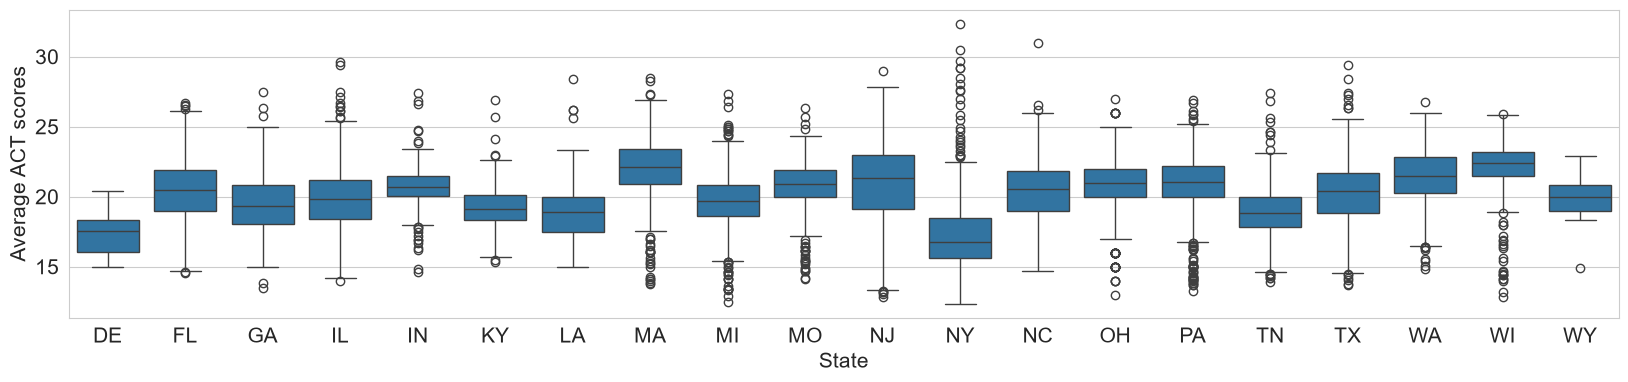

In [86]:
plt.figure(figsize = (20, 4))

sns.boxplot(data = df, x = 'state', y = 'act_avg')

plt.xlabel('State', fontsize = 15)
plt.ylabel('Average ACT scores', fontsize = 15)

plt.tick_params(labelsize = 15)

plt.savefig('C:\\Users\\portl\\OneDrive\\Documents\\Data Science Certificate\\DATA 5100 FQ\\Projects\\Education\\reports\\state_boxplot.jpg', dpi = 300, bbox_inches = 'tight')

plt.show()

Plot of mean ACT scores per state:

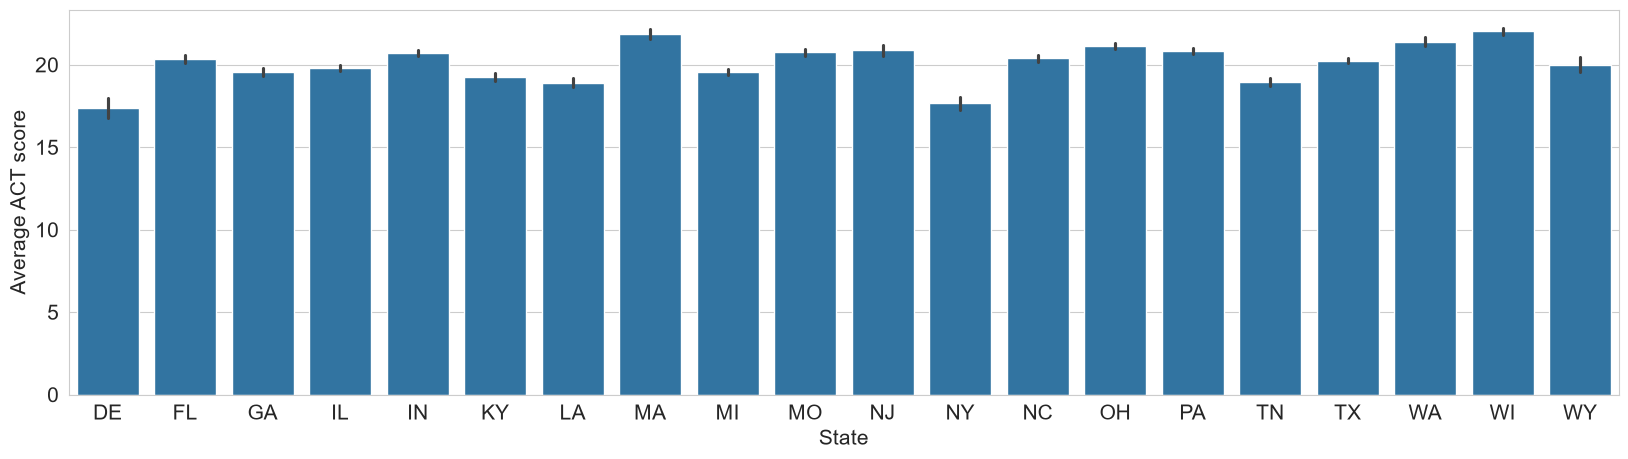

In [28]:
plt.figure(figsize = (20, 5))

sns.barplot(data = df, x = 'state', y = 'act_avg')

plt.xlabel('State', fontsize = 15)
plt.ylabel('Average ACT score', fontsize = 15)

plt.tick_params(labelsize = 15)

plt.show()

Comparing pct_lunch correlation values across states:

Assign individual state dataframes:

In [36]:
df_tx = df.loc[df['state'] == 'TX']
df_oh = df.loc[df['state'] == 'OH']
df_il = df.loc[df['state'] == 'IL']
df_pa = df.loc[df['state'] == 'PA']
df_mi = df.loc[df['state'] == 'MI']
df_nc = df.loc[df['state'] == 'NC']
df_fl = df.loc[df['state'] == 'FL']
df_ga = df.loc[df['state'] == 'GA']
df_wi = df.loc[df['state'] == 'WI']
df_nj = df.loc[df['state'] == 'NJ']
df_mo = df.loc[df['state'] == 'MO']
df_in = df.loc[df['state'] == 'IN']
df_ny = df.loc[df['state'] == 'NY']
df_tn = df.loc[df['state'] == 'TN']
df_wa = df.loc[df['state'] == 'WA']
df_ma = df.loc[df['state'] == 'MA']
df_ky = df.loc[df['state'] == 'KY']
df_la = df.loc[df['state'] == 'LA']
df_wy = df.loc[df['state'] == 'WY']
df_de = df.loc[df['state'] == 'DE']

Check for success:

In [50]:
df_tx

,id,unemployment_rate,pct_college,pct_married,median_income,act_avg,pct_lunch,year,state,zip,sch_type,level,charter
5662,480000801508,0.05,0.86,0.94,121406.0,24.57,0.07,2016-2017,TX,78620,Regular School,High,No
5663,480000906198,0.05,0.81,0.85,76073.0,23.50,0.19,2016-2017,TX,78676,Regular School,High,No
5664,480001005244,0.03,0.85,0.80,76141.0,21.57,0.32,2016-2017,TX,78610,Regular School,High,No
5665,480001009624,0.03,0.63,0.74,72462.0,19.44,0.48,2016-2017,TX,78640,Regular School,High,No
5666,480001100128,0.11,0.40,0.82,57037.0,19.27,0.39,2016-2017,TX,76009,Regular School,High,No
...,...,...,...,...,...,...,...,...,...,...,...,...,...
6570,484668005337,0.11,0.41,0.54,30093.0,15.81,0.78,2016-2017,TX,79915,Regular School,High,No
6571,484668005347,0.13,0.45,0.75,27688.0,15.66,0.80,2016-2017,TX,79907,Regular School,High,No
6572,484668006496,0.10,0.43,0.48,31603.0,16.51,0.72,2016-2017,TX,79907,Regular School,High,No
6573,484668011982,0.06,0.58,0.68,34063.0,20.84,0.49,2016-2017,TX,79915,Regular School,High,No


Full dataset correlation coefficient:

In [41]:
df[['pct_lunch'] + ['act_avg']].corr()

,pct_lunch,act_avg
pct_lunch,1.000000,-0.783097
act_avg,-0.783097,1.000000


List of our individual state dataframes:

In [37]:
state_dfs = [
    df_tx,
    df_oh,
    df_il,
    df_pa,
    df_mi,
    df_nc,
    df_fl,
    df_ga,
    df_wi,
    df_nj,
    df_mo,
    df_in,
    df_ny,
    df_tn,
    df_wa,
    df_ma,
    df_ky,
    df_la,
    df_wy,
    df_de
]

% lunch and average ACT correlations for each state:

In [48]:
for sdf in state_dfs:
    corr = np.corrcoef(sdf['pct_lunch'], sdf['act_avg'])[0][1]
    print(corr)

-0.7638631478713358
-0.6333464626226364
-0.8048639323483877
-0.8601937350864779
-0.8422868076323624
-0.796728479000361
-0.7490759723253397
-0.7877164787265998
-0.8146328973468849
-0.8770551572845229
-0.8063785611383926
-0.7198867014611704
-0.7763292108802816
-0.8512769339360423
-0.8302853650970028
-0.8501957573508693
-0.8156508946214349
-0.7925782247454973
-0.6671249811273477
-0.8289442833749078


Absolute difference between state correlation and overall correlation:

In [53]:
for sdf in state_dfs:
    corr = np.corrcoef(sdf['pct_lunch'], sdf['act_avg'])[0][1]
    print(round(abs(corr - -0.78309689), 4))

0.0192
0.1498
0.0218
0.0771
0.0592
0.0136
0.034
0.0046
0.0315
0.094
0.0233
0.0632
0.0068
0.0682
0.0472
0.0671
0.0326
0.0095
0.116
0.0458


The greatest difference between a single state's % lunch and average ACT score correlation is 0.1498 for OH, with most differences being much lower than that.

It seems unlikely that a deeper dive into individual states' relationships of these variables would yeild notably different results from our overall model.

# Conclusion

Our final predictive model only uses three of the five socioeconomic factors (unemployment_rate, pct_college, and pct_lunch), but the single variable models still show that median_income and pct_married do still hold some weight, just not as much as the other three.

We also did some exploration of subsets of the dataframe: whether a school was a charter school and by state. Neither of these cursory explorations pointed to any major differences in predictive outcomes from our final reduced model.